# EDA de los datos de la fuente del DGSIAP

### Pregunta de investigación: 
* Recordamos la pregunta de investigación para tener claro el enfoque durante este proceso:
**¿Qué relación tuvieron las variaciones de los precios regionales del maíz en México con los rendimientos mensuales de las acciones de Gruma en la Bolsa Mexicana de Valores entre 2013 y 2025?**

### 1. Cargamos los datos:

In [44]:
import pandas as pd
from rendimiento_bachoco.config import *
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

Especificamos algunas configuraciones para poder visualizar los datos claramente.

In [45]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

Cargamos un archivo .csv por año, desde `DGSIAP_START_YEAR` hasta `DGSIAP_END_YEAR`, ambos incluidos. Con la configuración actual, el intervalo es 2013–2025: 13 años (`DGSIAP_END_YEAR - DGSIAP_START_YEAR + 1`). Como `range()` excluye su límite superior, usamos `DGSIAP_END_YEAR + 1`. Comprobamos que los años cargados coincidan exactamente con el intervalo configurado, sin años faltantes ni posteriores al año final.

In [46]:
dgsiap_df = pd.DataFrame()
for year in range(DGSIAP_START_YEAR, DGSIAP_END_YEAR + 1):
    maiz = pd.read_csv(INTERIM_DATA_DIR / 'DGSIAP'/ f'{year}.csv')
    dgsiap_df = pd.concat([dgsiap_df, maiz])

anios_esperados_dgsiap = list(range(DGSIAP_START_YEAR, DGSIAP_END_YEAR + 1))
assert sorted(dgsiap_df['Anio'].unique().tolist()) == anios_esperados_dgsiap, (
    'La cobertura temporal no coincide con el intervalo DGSIAP inclusivo configurado.'
)


### 2.1 Primer análisis:


In [47]:
dgsiap_df.head()

,Unnamed: 0,Anio,Idestado,Nomestado,Idddr,Nomddr,Idcader,Nomcader,Idmunicipio,Nommunicipio,Idciclo,Nomcicloproductivo,Idmodalidad,Nommodalidad,Idunidadmedida,Nomunidad,Idcultivo,Nomcultivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Precio,Valorproduccion,Nomcultivo Sin Um,Preciomediorural
0,1,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Otoño-Invierno,1,Riego,200201,Tonelada,5490000,Avena forrajera en verde,798.0,798.0,0.0,21181.0,26.54,603.77,1.278845e+07,NaN,NaN
1,9,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,Primavera-Verano,1,Riego,200201,Tonelada,7470000,Maíz forrajero en verde,3187.0,3187.0,0.0,200503.0,62.91,615.49,1.234076e+08,NaN,NaN
2,10,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,Primavera-Verano,1,Riego,200201,Tonelada,7490000,Maíz grano,230.0,230.0,0.0,1699.0,7.39,3576.02,6.075658e+06,NaN,NaN
3,13,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,Primavera-Verano,2,Temporal,200201,Tonelada,5490000,Avena forrajera en verde,313.0,313.0,0.0,2497.0,7.98,470.28,1.174289e+06,NaN,NaN
4,15,2013,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,Primavera-Verano,2,Temporal,200201,Tonelada,7470000,Maíz forrajero en verde,14477.0,14477.0,0.0,146777.0,10.14,516.43,7.580005e+07,NaN,NaN


In [48]:
dgsiap_df.shape

(100922, 27)

Obtenemos un primer vistazo sobre los datos:

In [49]:
dgsiap_df.columns.tolist()

['Unnamed: 0',
 'Anio',
 'Idestado',
 'Nomestado',
 'Idddr',
 'Nomddr',
 'Idcader',
 'Nomcader',
 'Idmunicipio',
 'Nommunicipio',
 'Idciclo',
 'Nomcicloproductivo',
 'Idmodalidad',
 'Nommodalidad',
 'Idunidadmedida',
 'Nomunidad',
 'Idcultivo',
 'Nomcultivo',
 'Sembrada',
 'Cosechada',
 'Siniestrada',
 'Volumenproduccion',
 'Rendimiento',
 'Precio',
 'Valorproduccion',
 'Nomcultivo Sin Um',
 'Preciomediorural']

In [50]:
dgsiap_df.info()

<class 'pandas.DataFrame'>
Index: 100922 entries, 0 to 7709
Data columns (total 27 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Unnamed: 0          100922 non-null  int64  
 1   Anio                100922 non-null  int64  
 2   Idestado            100922 non-null  int64  
 3   Nomestado           100922 non-null  str    
 4   Idddr               100922 non-null  int64  
 5   Nomddr              100922 non-null  str    
 6   Idcader             100922 non-null  int64  
 7   Nomcader            100922 non-null  str    
 8   Idmunicipio         100922 non-null  int64  
 9   Nommunicipio        100922 non-null  str    
 10  Idciclo             100922 non-null  int64  
 11  Nomcicloproductivo  100922 non-null  str    
 12  Idmodalidad         100922 non-null  int64  
 13  Nommodalidad        100922 non-null  str    
 14  Idunidadmedida      100922 non-null  int64  
 15  Nomunidad           100922 non-null  str    
 16  Id

Observaciones: 
- Las columnas 'Nomcultivo' y 'Nomcultivo Sin Um' son el mismo atributo, pero hay una inconsistencia en el nombre de la variable por eso se observan los valores nulos.
- Es el mismo caso de 'precio' y 'Preciomediorural'.
- Además de las diferencias de nombres, `Rendimiento` contiene valores faltantes en 2024 y 2025; se revisan junto con los precios faltantes más adelante.

Analizamos que las inconsistencias embonen en cantidades de valores nulos:

In [51]:
dgsiap_df['Nomcultivo'].isnull().sum() + dgsiap_df['Nomcultivo Sin Um'].isnull().sum() == dgsiap_df.shape[0]

np.True_

In [52]:
dgsiap_df['Precio'].isnull().sum() + dgsiap_df['Preciomediorural'].isnull().sum() == dgsiap_df.shape[0]

np.False_

Podemos ver que nuestra suposición se verifica con 'Nomcultivo', pero no con 'Precio'. Sin embargo, podemos ver en los metadatos que 'Precio' se describe como 'Preciomediorural', por lo que podemos asumir que es la misma variable. Investigamos los valores faltantes que restan en la columna de 'Precio'. En el intervalo inclusivo 2013–2025, el cálculo siguiente identifica 64 entradas faltantes entre todos los cultivos cargados:

In [53]:
dgsiap_df[['Precio', 'Preciomediorural']].isnull().sum().agg('sum') - dgsiap_df.shape[0]

np.int64(64)

Tomamos el primer subconjunto de los datos, en particular los datos que contienen el cultivo de interés, el maíz:

In [54]:
maiz = dgsiap_df.loc[(dgsiap_df['Nomcultivo'] == 'Maíz grano') | (dgsiap_df['Nomcultivo Sin Um'] == 'Maíz grano')]
maiz = maiz.drop(columns = 'Unnamed: 0') # Remanente del index en la fuente de datos raw

Reemplazamos las entradas faltantes de 'Precio' con las entradas de 'Preciomediorural':

In [55]:
maiz['Precio'] = maiz['Precio'].fillna(maiz['Preciomediorural'])
maiz = maiz.drop(columns = 'Preciomediorural')

Hacemos lo mismo con 'Nomcultivo':

In [56]:
maiz['Nomcultivo'] = maiz['Nomcultivo'].fillna(maiz['Nomcultivo Sin Um'])
maiz = maiz.drop(columns = 'Nomcultivo Sin Um')

In [57]:
maiz.isna().sum()

Anio                   0
Idestado               0
Nomestado              0
Idddr                  0
Nomddr                 0
Idcader                0
Nomcader               0
Idmunicipio            0
Nommunicipio           0
Idciclo                0
Nomcicloproductivo     0
Idmodalidad            0
Nommodalidad           0
Idunidadmedida         0
Nomunidad              0
Idcultivo              0
Nomcultivo             0
Sembrada               0
Cosechada              0
Siniestrada            0
Volumenproduccion      0
Rendimiento           29
Precio                29
Valorproduccion        0
dtype: int64

Y descubrimos los verdaderos valores faltantes

In [58]:
maiz.loc[(maiz['Rendimiento'].isnull()) | (maiz['Precio'].isnull())]

,Anio,Idestado,Nomestado,Idddr,Nomddr,Idcader,Nomcader,Idmunicipio,Nommunicipio,Idciclo,Nomcicloproductivo,Idmodalidad,Nommodalidad,Idunidadmedida,Nomunidad,Idcultivo,Nomcultivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Precio,Valorproduccion
283,2024,5,Coahuila,192,Laguna-Coahuila,11,Torreón,35,Torreón,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,19.00,0.0,19.00,0.0,NaN,NaN,0.0
582,2024,8,Chihuahua,28,Casas Grandes,1,Nuevo Casas Grandes,13,Casas Grandes,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,100.00,0.0,100.00,0.0,NaN,NaN,0.0
588,2024,8,Chihuahua,28,Casas Grandes,1,Nuevo Casas Grandes,50,Nuevo Casas Grandes,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,50.00,0.0,50.00,0.0,NaN,NaN,0.0
596,2024,8,Chihuahua,28,Casas Grandes,2,Janos,35,Janos,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,100.00,0.0,100.00,0.0,NaN,NaN,0.0
1137,2024,10,Durango,191,Laguna-Durango,4,Sn. Pedro El Gallo,30,San Pedro del Gallo,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,705.00,0.0,705.00,0.0,NaN,NaN,0.0
1167,2024,10,Durango,191,Laguna-Durango,16,Rodeo,24,Rodeo,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,725.50,0.0,725.50,0.0,NaN,NaN,0.0
1176,2024,10,Durango,191,Laguna-Durango,18,Bermejillo,13,Mapimí,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,40.00,0.0,40.00,0.0,NaN,NaN,0.0
6075,2024,24,San Luis Potosí,129,Rioverde,1,Cárdenas,2,Alaquines,1,Otoño-Invierno,2,Temporal,200201,Tonelada,7490000,Maíz grano,25.00,0.0,25.00,0.0,NaN,NaN,0.0
6186,2024,25,Sinaloa,133,Los Mochis,2,El Fuerte,10,El Fuerte,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,100.00,0.0,100.00,0.0,NaN,NaN,0.0
6447,2024,26,Sonora,148,Cajeme,6,Rosario,49,Quiriego,2,Primavera-Verano,2,Temporal,200201,Tonelada,7490000,Maíz grano,25.00,0.0,25.00,0.0,NaN,NaN,0.0


En el maíz, los 29 registros con rendimiento o precio faltante corresponden a 19 casos de 2024 y 10 de 2025. En todos ellos, la superficie 'Siniestrada' es igual a la 'Sembrada' y la 'Cosechada' es 0.0. Conservamos el tratamiento existente de reemplazar esos faltantes con ceros para procesarlos junto con el resto del conjunto. Un precio cero sin producción no representa una transacción observada a precio cero; la sección 3 compara su efecto sobre las medias.

In [59]:
maiz['Rendimiento'] = maiz['Rendimiento'].fillna(0.0) 
maiz['Precio'] = maiz['Precio'].fillna(0.0) 
maiz.isna().sum()

Anio                  0
Idestado              0
Nomestado             0
Idddr                 0
Nomddr                0
Idcader               0
Nomcader              0
Idmunicipio           0
Nommunicipio          0
Idciclo               0
Nomcicloproductivo    0
Idmodalidad           0
Nommodalidad          0
Idunidadmedida        0
Nomunidad             0
Idcultivo             0
Nomcultivo            0
Sembrada              0
Cosechada             0
Siniestrada           0
Volumenproduccion     0
Rendimiento           0
Precio                0
Valorproduccion       0
dtype: int64

Buscamos anomalías basándonos en la última observación, tomando en cuenta que el volumen de 'Sembrada' debe ser igual a 'Siniestra' más 'Cosechada': 

In [60]:
maiz['VolumenCosechaCalculado'] = maiz['Cosechada'] + maiz['Siniestrada']
maiz['VolumenCosechaCalculado'] = (maiz['Cosechada'] + maiz['Siniestrada']).round(decimals=2)
len(maiz[maiz['VolumenCosechaCalculado'] > maiz['Sembrada']])

0

Buscamos anomalías haciendo una observación similar, pero en el caso del rendimiento y observamos que no hay anomalías en este caso:

In [61]:
mask_cosechada = maiz['Cosechada'] > 0 # Evitar división por cero
maiz['RendimientoCalculado'] = np.where(mask_cosechada, maiz['Volumenproduccion'] / maiz['Sembrada'], 0).round(decimals = 2)
err_inf = maiz['RendimientoCalculado'] - 0.01
err_sup = maiz['RendimientoCalculado'] + 0.01
len(maiz.loc[(maiz['Rendimiento'] < err_inf) & (maiz['Rendimiento'] > err_sup)])

0

In [62]:
maiz.columns.tolist()

['Anio',
 'Idestado',
 'Nomestado',
 'Idddr',
 'Nomddr',
 'Idcader',
 'Nomcader',
 'Idmunicipio',
 'Nommunicipio',
 'Idciclo',
 'Nomcicloproductivo',
 'Idmodalidad',
 'Nommodalidad',
 'Idunidadmedida',
 'Nomunidad',
 'Idcultivo',
 'Nomcultivo',
 'Sembrada',
 'Cosechada',
 'Siniestrada',
 'Volumenproduccion',
 'Rendimiento',
 'Precio',
 'Valorproduccion',
 'VolumenCosechaCalculado',
 'RendimientoCalculado']

Ahora sabemos que, aunque hayan valores con 0.0, esto no implica que sean valores faltantes si no que indican una cosecha fallida. Al momento de hace un análisis, habrá que tratar estos valores de manera específica para que no afecten las estadísticas descriptivas como valores outlier, cuando en realidad indican algo=una situación en particular.

### 2.2 Auto-EDA:

                                             |                                                                …

findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfo


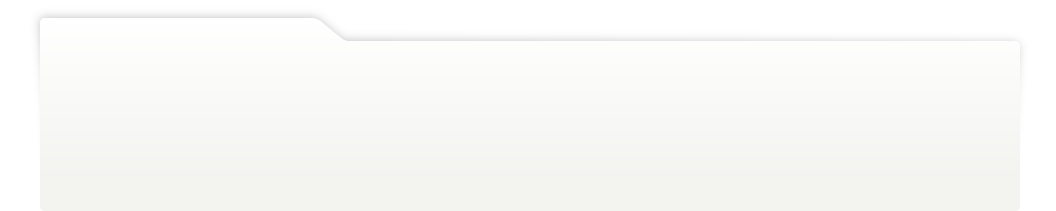
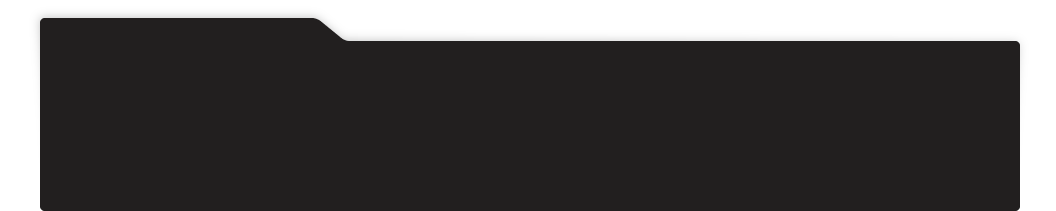
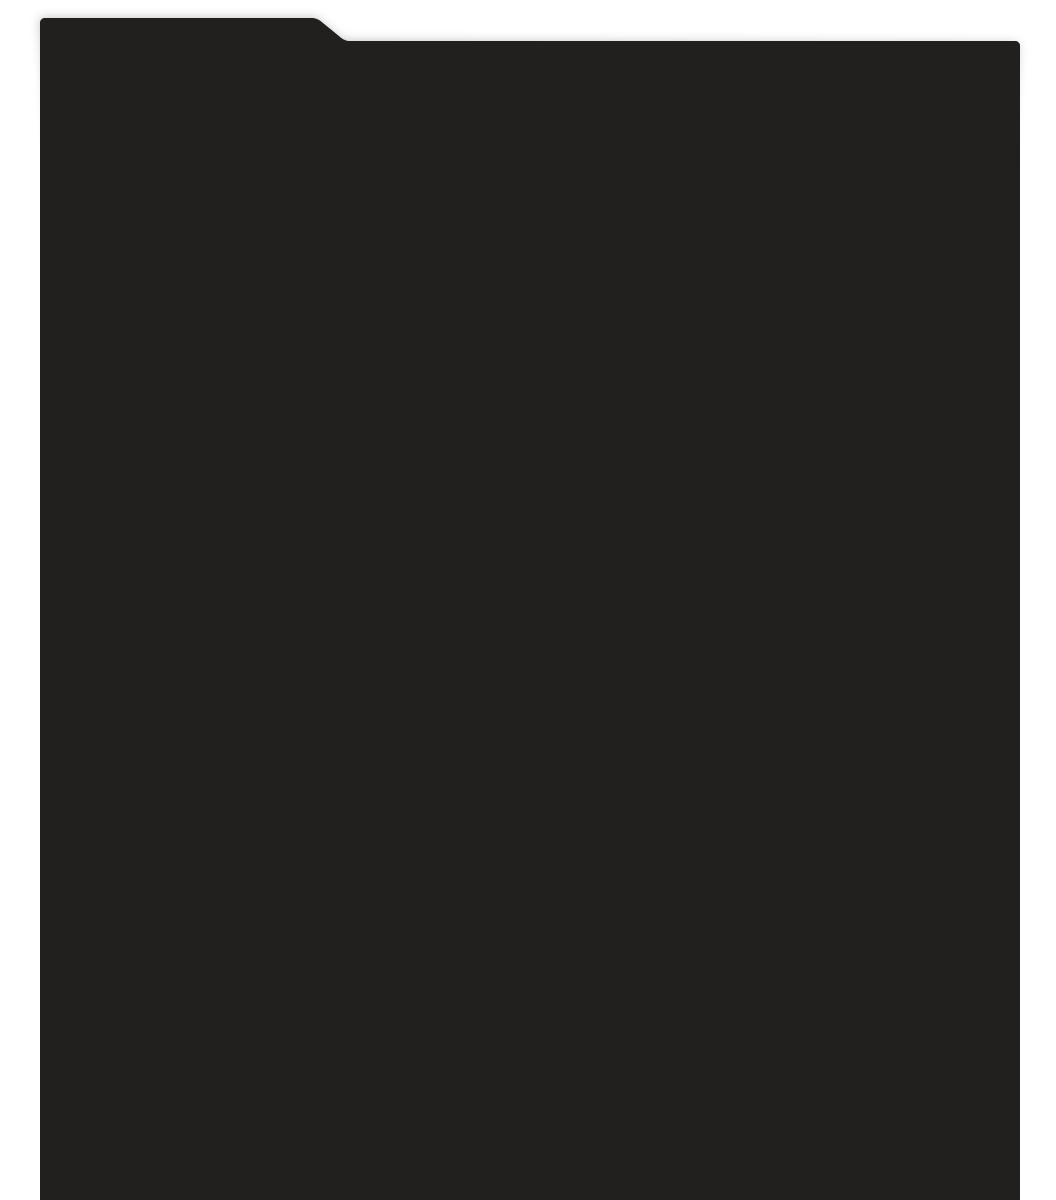
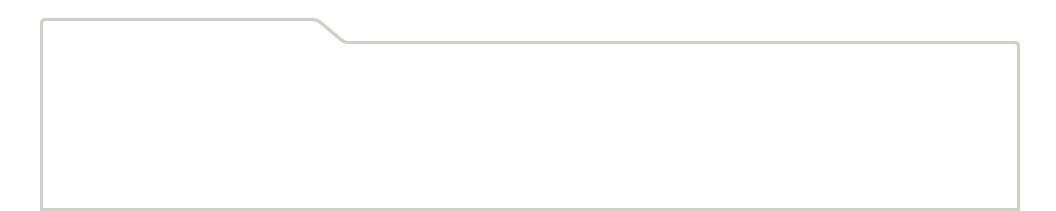
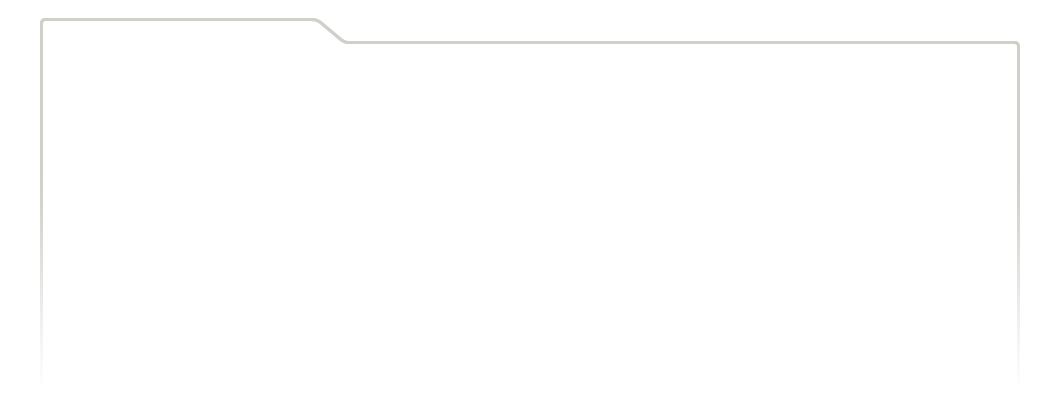
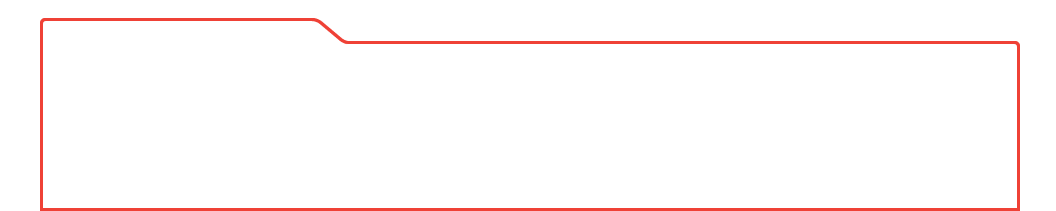
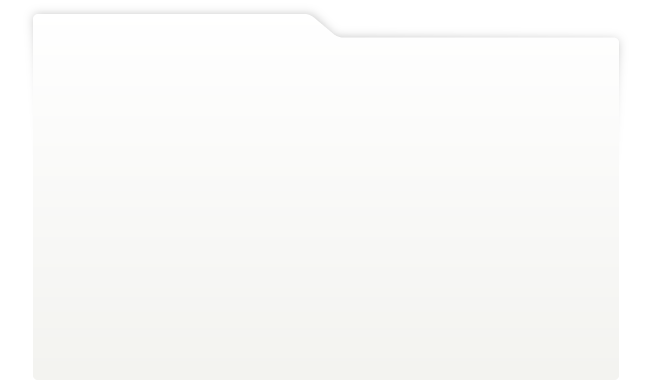
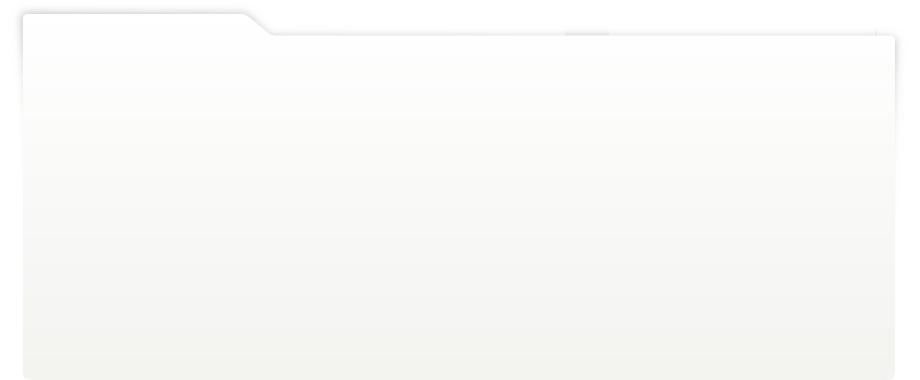
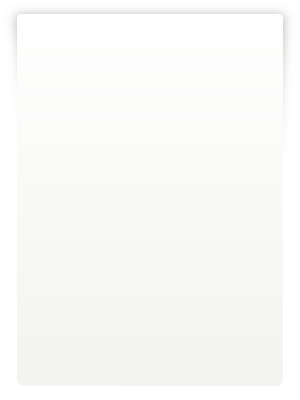
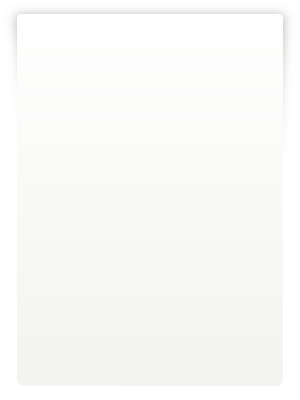
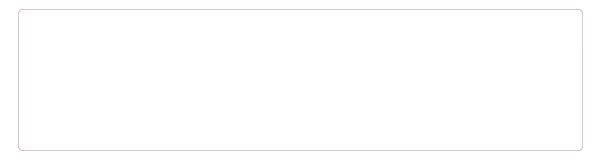
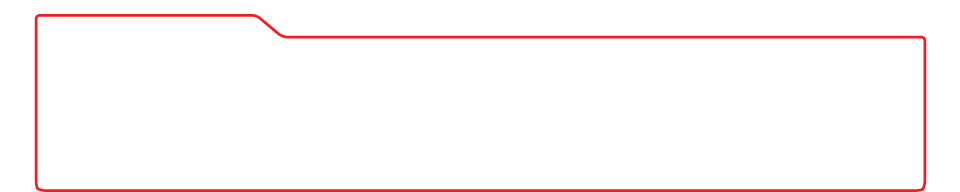
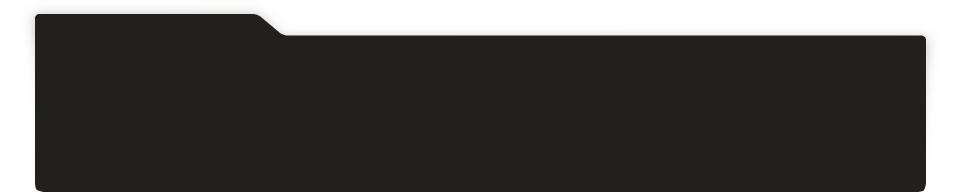
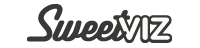
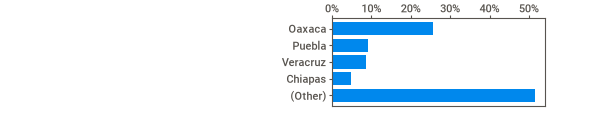
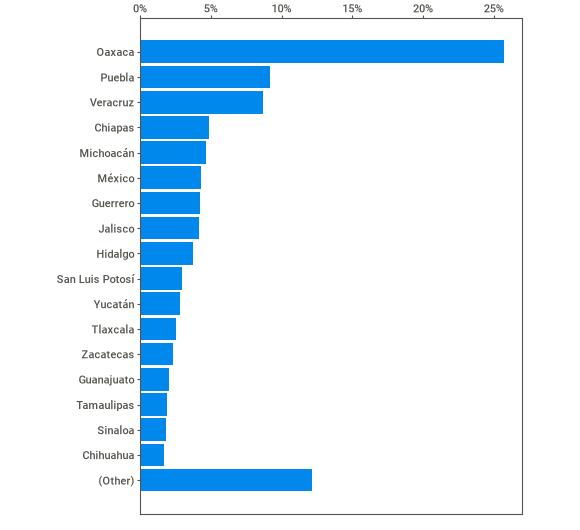
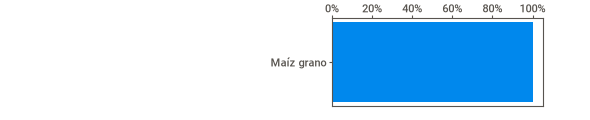
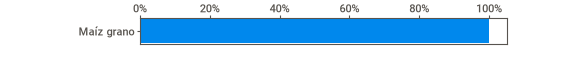
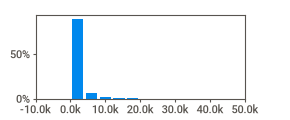
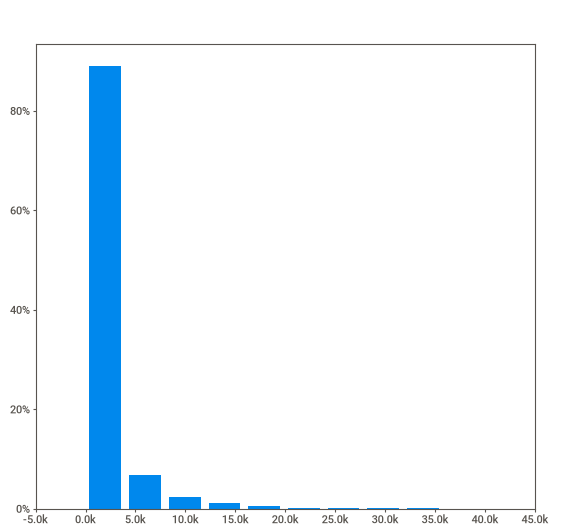
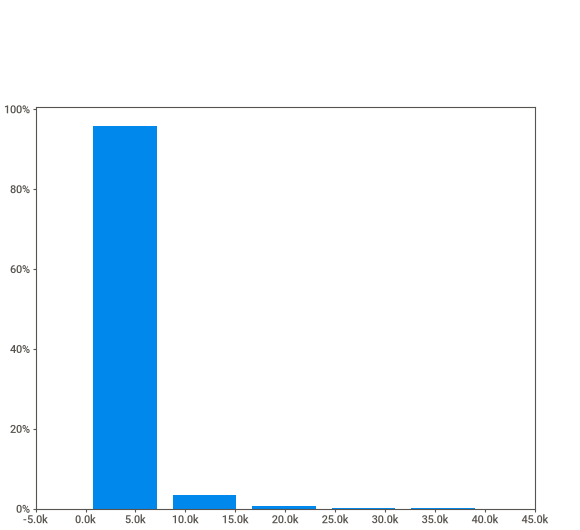
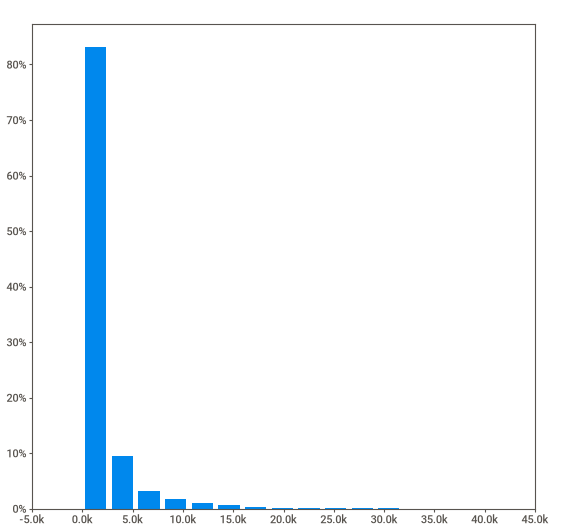
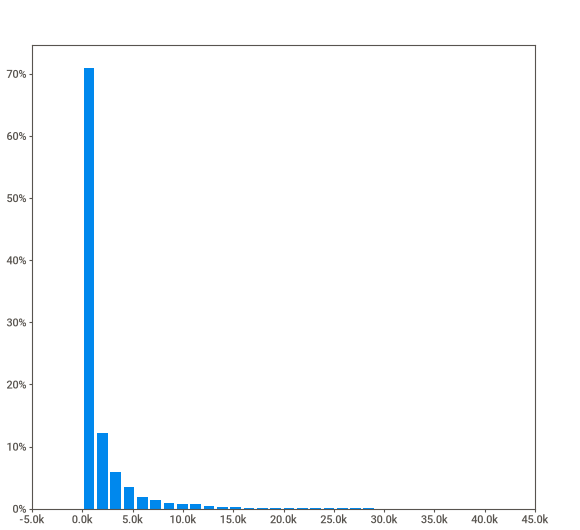
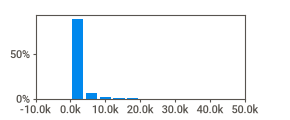
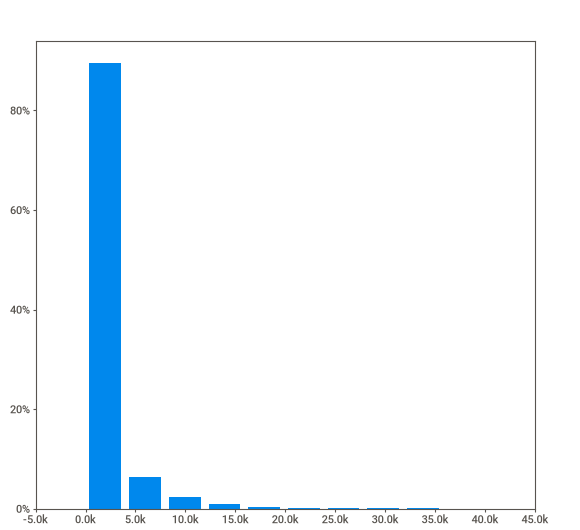
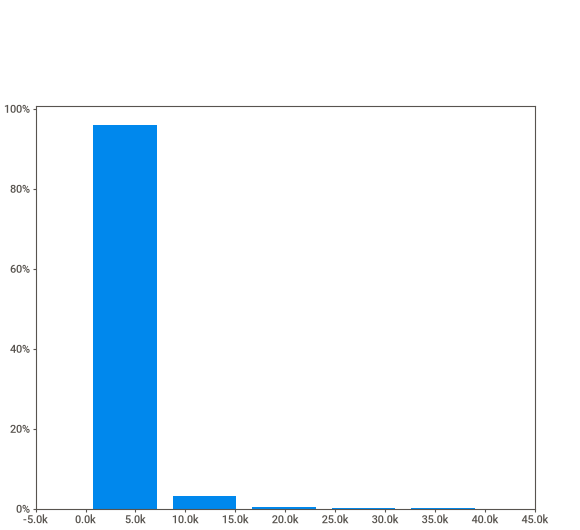
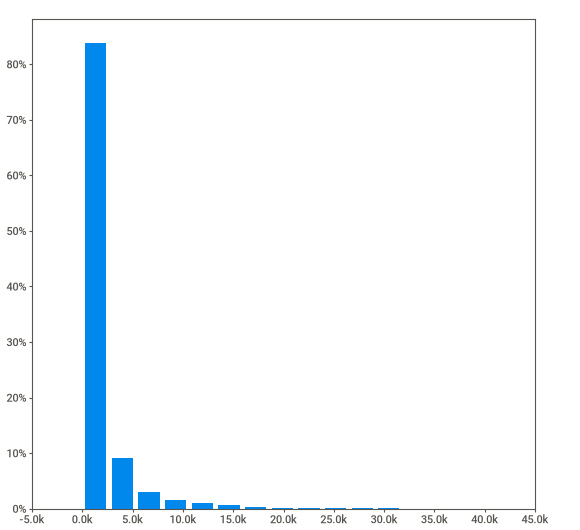
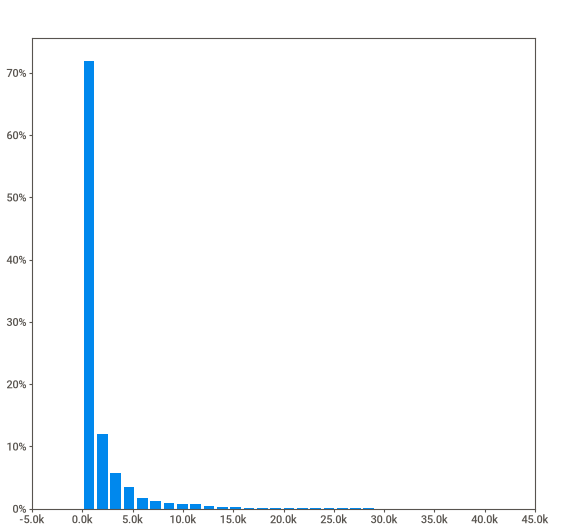
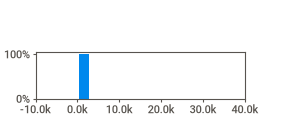
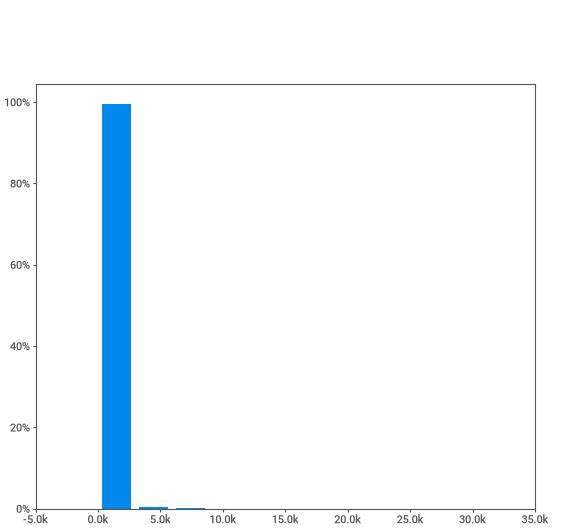
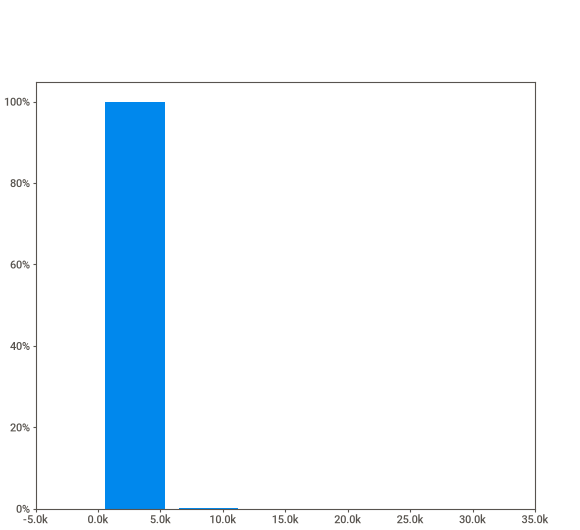
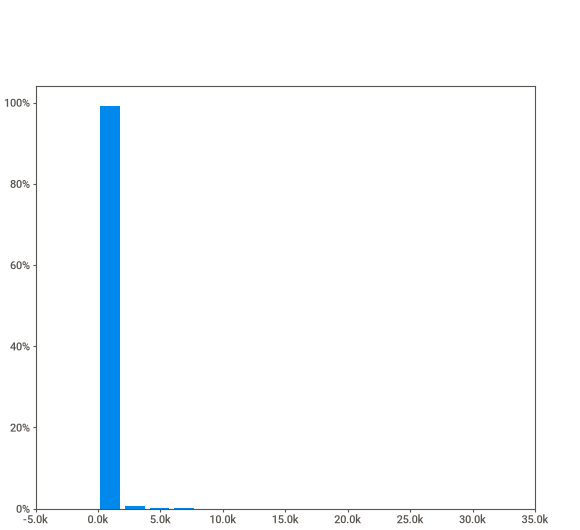
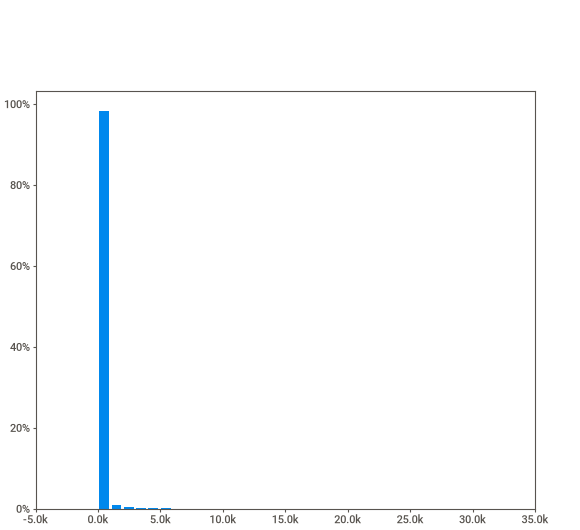
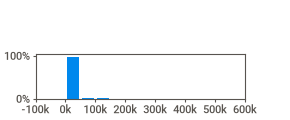
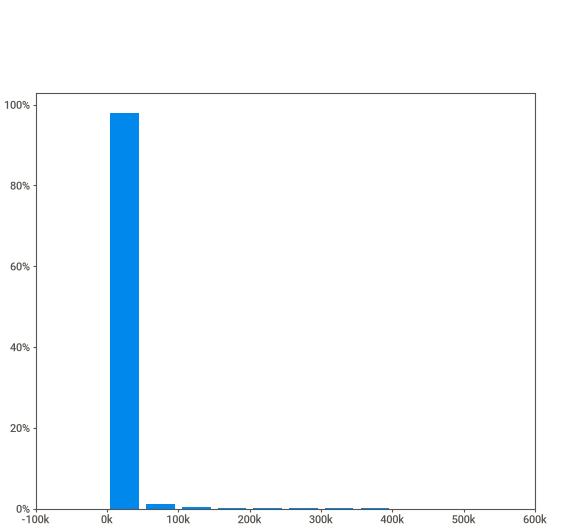
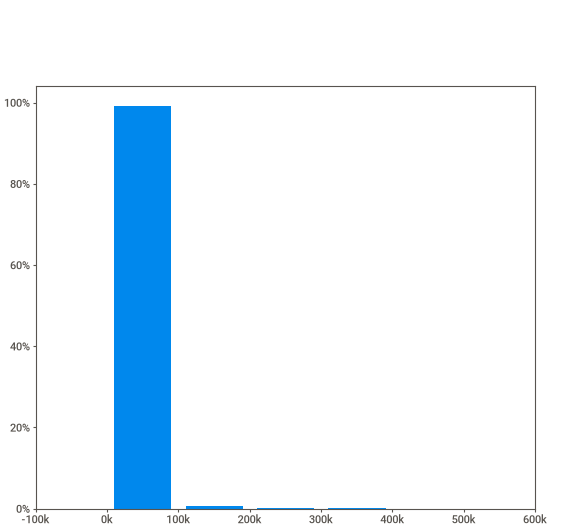
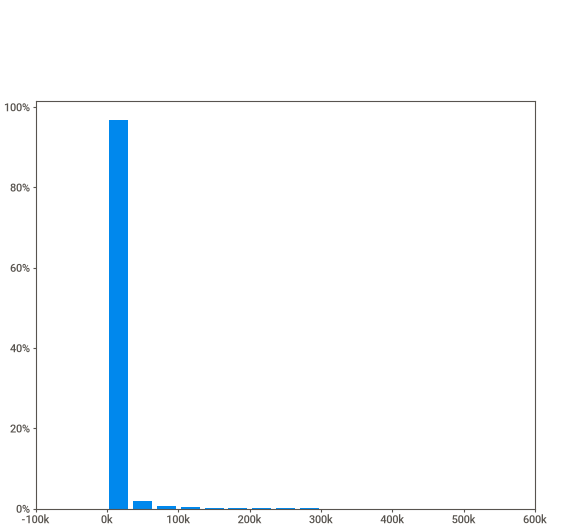
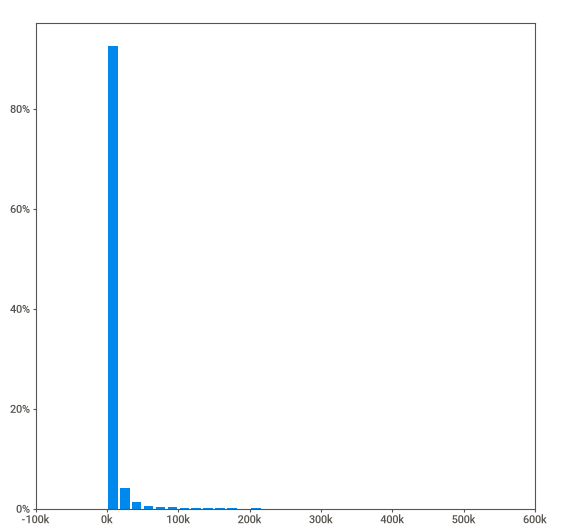
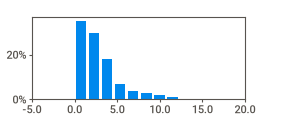
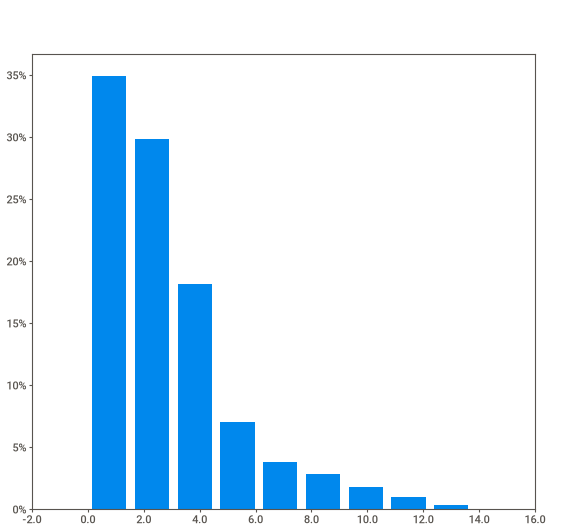
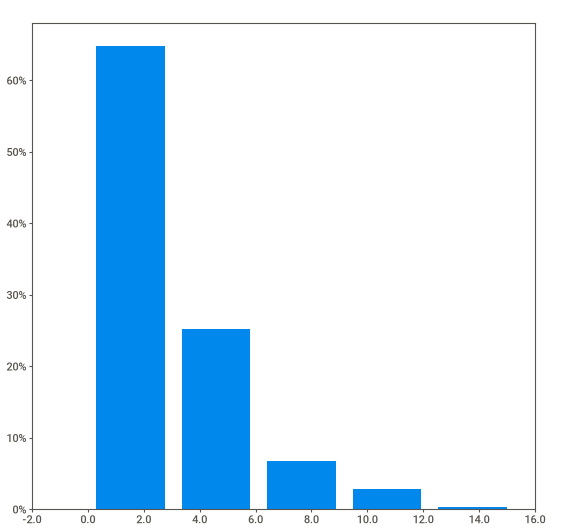
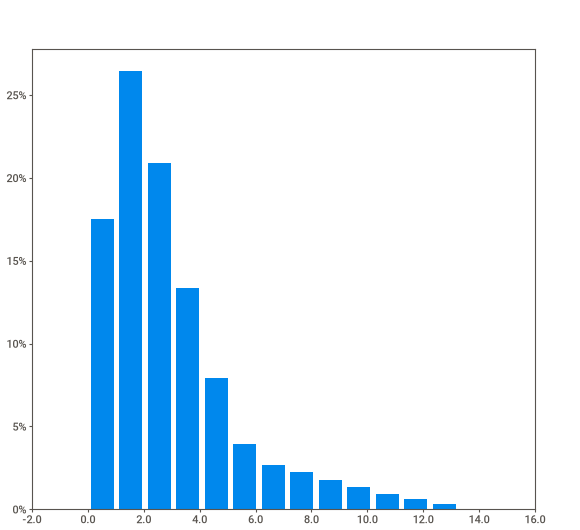
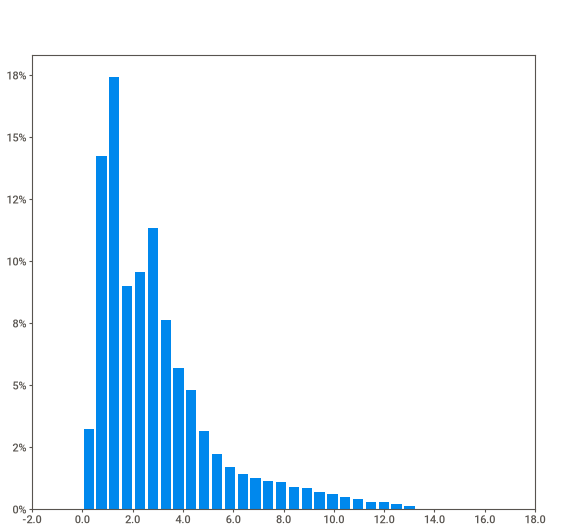
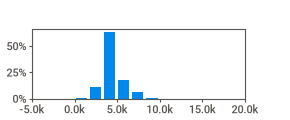
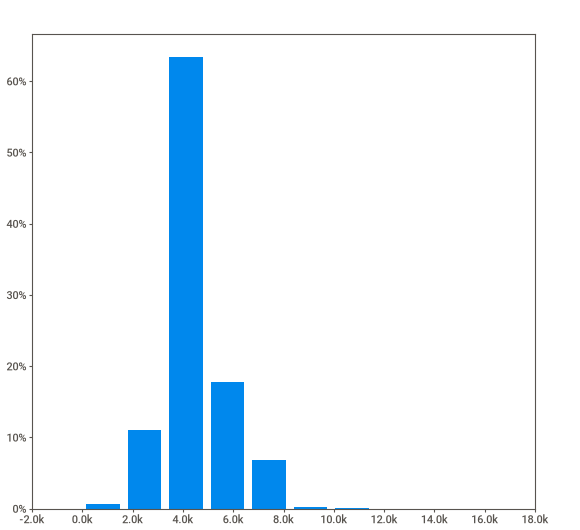
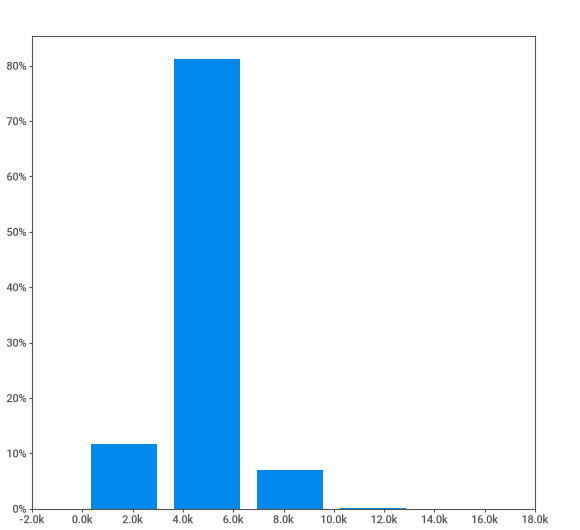
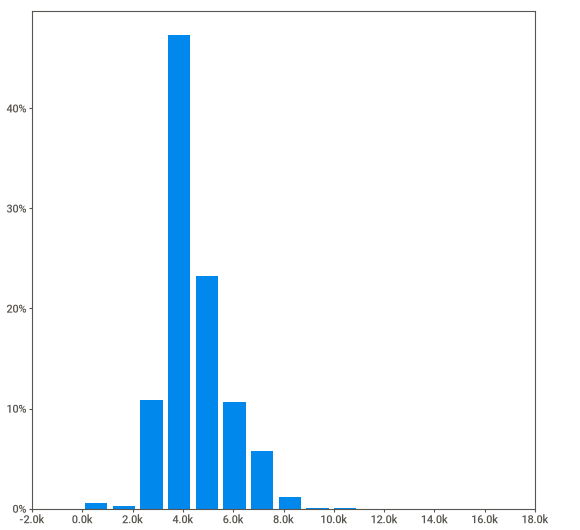
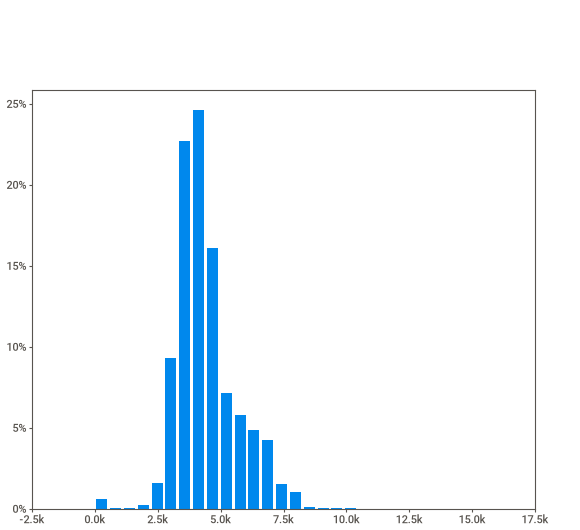
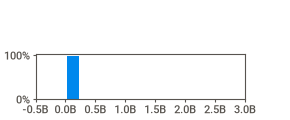
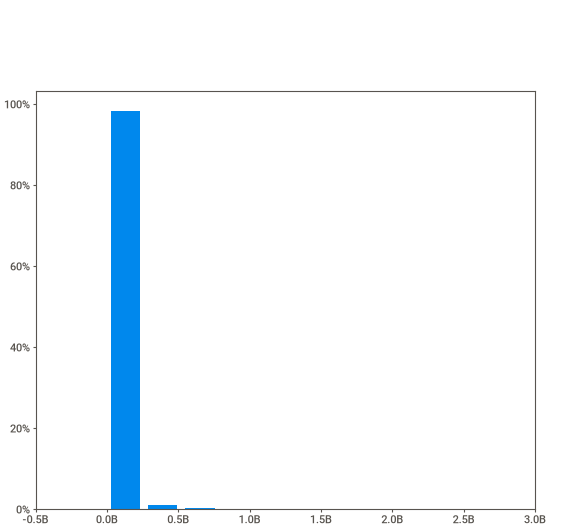
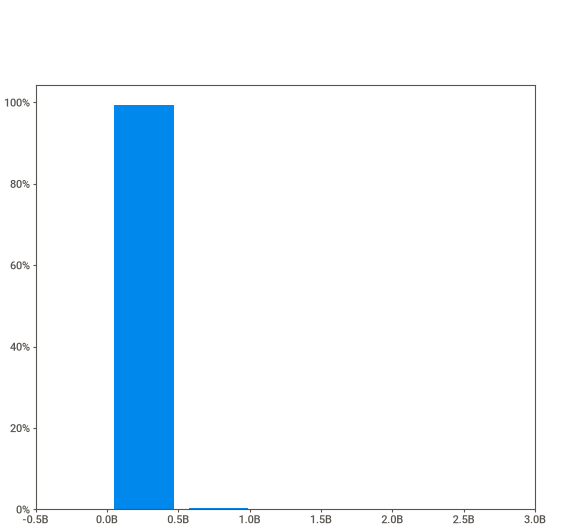
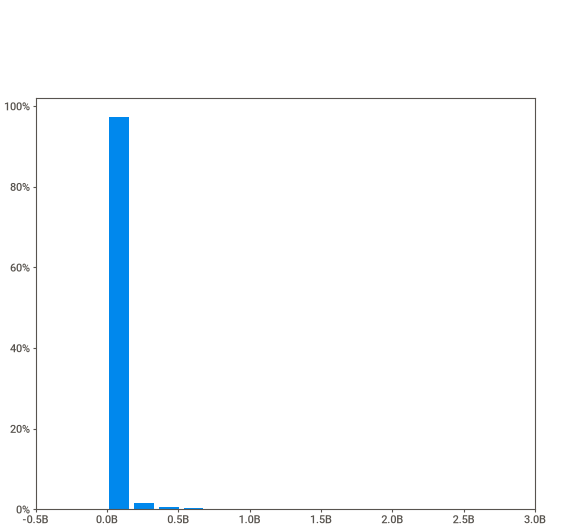
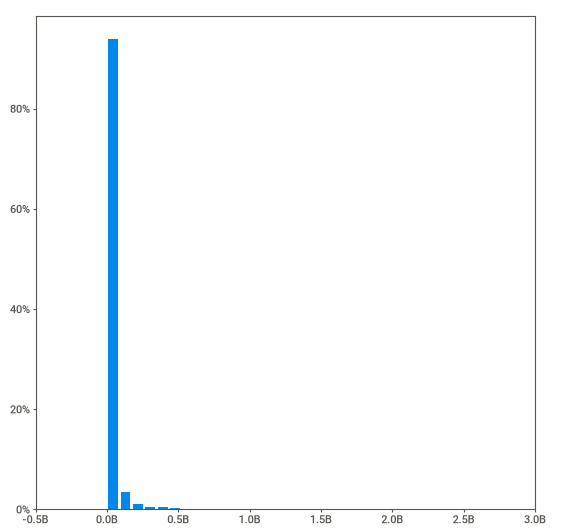
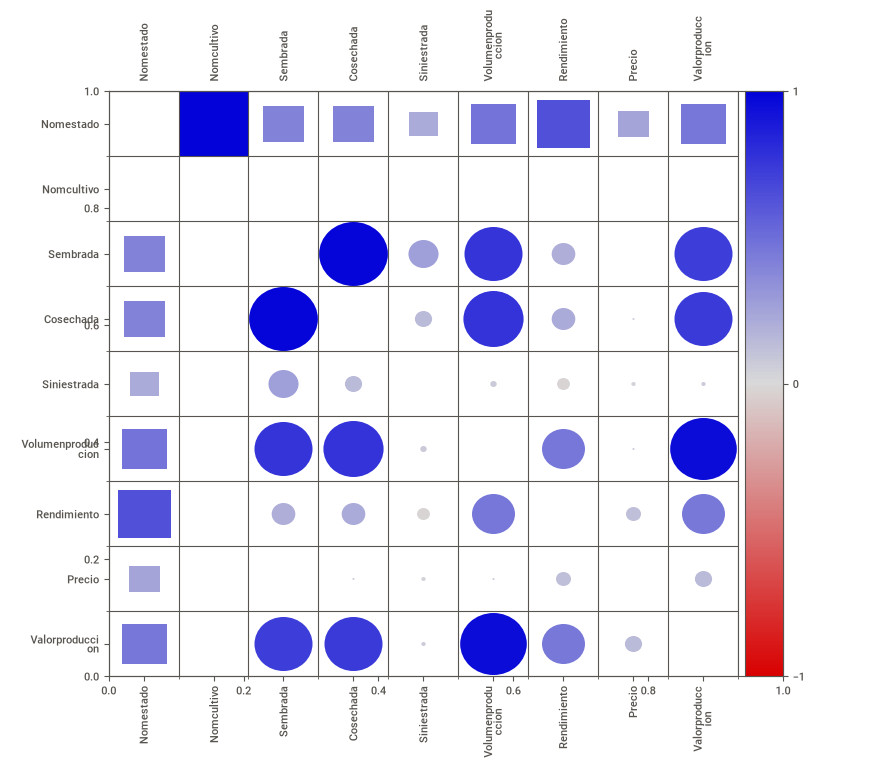
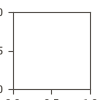

In [63]:
import sweetviz as sv
report = sv.analyze(maiz[[
    'Nomestado',
    'Nomcultivo',
    'Sembrada',
    'Cosechada',
    'Siniestrada',
    'Volumenproduccion',
    'Rendimiento',
    'Precio',
    'Valorproduccion',]])
report.show_notebook()

### 3 Análisis Descriptivo Uni-Variable

Tomamos un primer vistazo a las estadísticas:

In [64]:
maiz.describe()

,Anio,Idestado,Idddr,Idcader,Idmunicipio,Idciclo,Idmodalidad,Idunidadmedida,Idcultivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Precio,Valorproduccion,VolumenCosechaCalculado,RendimientoCalculado
count,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,59856.0,59856.0,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,59856.000000,5.985600e+04,59856.000000,59856.000000
mean,2019.002539,19.275511,103.585739,2.550605,114.266239,1.725658,1.612236,200201.0,7490000.0,1576.824696,1516.409593,60.415102,5660.538913,2.945679,4414.997069,2.534757e+07,1576.824696,2.903094
std,3.736742,7.138717,45.719123,1.766972,138.321981,0.446186,0.487244,0.0,0.0,3088.931910,3017.985451,430.953289,20548.859462,2.345819,1210.244261,9.531135e+07,3088.931910,2.350178
min,2013.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,200201.0,7490000.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2016.000000,14.000000,71.000000,1.000000,22.000000,1.000000,1.000000,200201.0,7490000.0,78.400000,73.000000,0.000000,155.800000,1.220000,3640.000000,6.533597e+05,78.400000,1.200000
50%,2019.000000,20.000000,105.000000,2.000000,58.000000,2.000000,2.000000,200201.0,7490000.0,415.000000,392.000000,0.000000,740.000000,2.380000,4149.615000,3.147492e+06,415.000000,2.340000
75%,2022.000000,24.000000,128.000000,3.000000,144.000000,2.000000,2.000000,200201.0,7490000.0,1678.000000,1580.000000,0.000000,3348.120000,3.800000,4937.587500,1.440844e+07,1678.000000,3.780000
max,2025.000000,32.000000,193.000000,18.000000,570.000000,2.000000,2.000000,200201.0,7490000.0,39742.000000,39742.000000,29598.660000,500812.000000,15.300000,16500.000000,2.601964e+09,39742.000000,15.300000


In [65]:
maiz.describe(include = ['object', 'str'])

,Nomestado,Nomddr,Nomcader,Nommunicipio,Nomcicloproductivo,Nommodalidad,Nomunidad,Nomcultivo
count,59856,59856,59856,59856,59856,59856,59856,59856
unique,33,188,665,2286,2,2,1,1
top,Oaxaca,Valles Centrales,Etla,Sinaloa,Primavera-Verano,Temporal,Tonelada,Maíz grano
freq,15394,5274,2911,156,43435,36646,59856,59856


A continuación tomamos el subconjunto de interés con los estados de los mercadoes relevantes (Sinaloa, Sonora, Jalisco, Ciudad de México, Nuevo León):

In [66]:
# Restringimos el análisis a los estados de interés; CDMX aparece en la fuente con dos nombres.
estados_seleccionados = ['Sinaloa', 'Sonora', 'Jalisco', 'Ciudad de México', 'Nuevo León']
nombres_estados_seleccionados = estados_seleccionados + ['Ciudad de México / DF']
maiz = maiz.loc[maiz['Nomestado'].isin(nombres_estados_seleccionados)].reset_index(drop=True)
assert maiz['Idestado'].nunique() == len(estados_seleccionados), (
    'Algún estado seleccionado no tiene registros de maíz grano.'
)
maiz.groupby('Nomestado')['Anio'].agg(['nunique', 'size'])


,nunique,size
Nomestado,,
Ciudad de México,11,77
Ciudad de México / DF,2,14
Jalisco,13,2513
Nuevo León,13,566
Sinaloa,13,1092
Sonora,13,832


#### 3.1 Alcance, cobertura y unidad de observación

Estudiamos `Rendimiento` (toneladas/hectárea), `Precio` (pesos/tonelada), `Valorproduccion` (pesos corrientes) y `Volumenproduccion` (toneladas). Los registros originales distinguen año, ubicación, ciclo agrícola y modalidad hídrica; no representan observaciones independientes de un experimento.

Trabajamos sobre una **copia de `maiz`**, sin modificar su preparación previa. Unificamos `Ciudad de México / DF` y `Ciudad de México`, que comparten `Idestado = 9`, para no dividir artificialmente su historia. El periodo se obtiene de los datos efectivamente cargados y debe coincidir con el intervalo configurado, incluidos ambos extremos: 2013–2025 (13 años) con la configuración actual. La carga usa `DGSIAP_END_YEAR + 1` para incluir el año final.

Conservamos los ceros y los extremos. Un volumen cero no se elimina como dato atípico; revisamos su relación con la superficie cosechada y siniestrada. En particular, un precio cero sin producción no equivale a una transacción realizada a precio cero.

In [67]:
# Reutilizamos las bibliotecas importadas y añadimos utilidades de presentación.
from IPython.display import Markdown, display
from matplotlib.colors import Normalize

variables_univariables = ['Rendimiento', 'Precio', 'Valorproduccion', 'Volumenproduccion']
claves_univariables = ['Nomestado', 'Anio']
auxiliares_univariables = ['Idestado', 'Sembrada', 'Cosechada', 'Siniestrada']
maiz_univariable = maiz[claves_univariables + auxiliares_univariables + variables_univariables].copy()

# Mostramos la equivalencia geográfica antes de normalizarla exclusivamente en la copia.
equivalencias_cdmx = maiz_univariable.loc[
    maiz_univariable['Idestado'].eq(9), ['Idestado', 'Nomestado']
].drop_duplicates().reset_index(drop=True)
display(equivalencias_cdmx)
maiz_univariable['Nomestado'] = maiz_univariable['Nomestado'].replace(
    {'Ciudad de México / DF': 'Ciudad de México'}
)
anios_univariables = sorted(maiz_univariable['Anio'].unique())
periodo_univariable = f'{anios_univariables[0]}–{anios_univariables[-1]}'
sin_produccion = maiz_univariable['Volumenproduccion'].eq(0)

# El diagnóstico distingue ausencia, cero y valores negativos sin corregirlos silenciosamente.
diagnostico_univariable = pd.DataFrame({
    'Registros válidos': maiz_univariable[variables_univariables].count(),
    'Faltantes': maiz_univariable[variables_univariables].isna().sum(),
    'Ceros': maiz_univariable[variables_univariables].eq(0).sum(),
    'Negativos': maiz_univariable[variables_univariables].lt(0).sum(),
}).rename_axis('Variable').reset_index()
display(Markdown(
    f'**Cobertura:** {len(maiz_univariable):,} registros; '
    f'{maiz_univariable.Nomestado.nunique()} estados; periodo {periodo_univariable}.'
))
display(diagnostico_univariable)
display(pd.DataFrame({
    'Condición': ['Sin producción', 'Sin producción y sin superficie cosechada',
                 'Sin producción y superficie sembrada igual a siniestrada',
                 'Precio cero con producción positiva'],
    'Registros': [sin_produccion.sum(),
                  (sin_produccion & maiz_univariable.Cosechada.eq(0)).sum(),
                  (sin_produccion & np.isclose(maiz_univariable.Sembrada,
                                               maiz_univariable.Siniestrada, rtol=0, atol=0.01)).sum(),
                  (maiz_univariable.Precio.eq(0) & maiz_univariable.Volumenproduccion.gt(0)).sum()],
}))

,Idestado,Nomestado
0,9,Ciudad de México / DF
1,9,Ciudad de México


**Cobertura:** 5,094 registros; 5 estados; periodo 2013–2025.

,Variable,Registros válidos,Faltantes,Ceros,Negativos
0,Rendimiento,5094,0,52,0
1,Precio,5094,0,52,0
2,Valorproduccion,5094,0,52,0
3,Volumenproduccion,5094,0,52,0


,Condición,Registros
0,Sin producción,52
1,Sin producción y sin superficie cosechada,52
2,Sin producción y superficie sembrada igual a siniestrada,52
3,Precio cero con producción positiva,0


#### 3.2 Agregación por estado y año

Creamos **cuatro dataframes independientes**, con una fila por combinación `Nomestado`–`Anio` y un índice simple mediante `.reset_index()`. Conservar el año permite construir las series temporales sin asignar un año arbitrario a un resumen de todo el periodo.

- `rendimiento_estado_anio`: **media simple** del rendimiento de los registros; no es el cociente entre producción total y superficie cosechada total.
- `precio_estado_anio`: **media simple** del precio; no está ponderada por toneladas producidas.
- `valorproduccion_estado_anio`: **valor medio por registro**, no valor total estatal.
- `volumenproduccion_estado_anio`: **suma de la producción anual estatal**.

Todos incluyen los registros sin producción. La tabla de cobertura permite revisar cuántos registros contribuyen a cada agregado: las medias simples pueden cambiar cuando cambia la composición de los registros.

In [68]:
# Agrupamos siempre por las mismas claves; sort=True mantiene un orden reproducible.
rendimiento_estado_anio = (
    maiz_univariable.groupby(claves_univariables, sort=True)['Rendimiento']
    .agg('mean').reset_index()
)
precio_estado_anio = (
    maiz_univariable.groupby(claves_univariables, sort=True)['Precio']
    .agg('mean').reset_index()
)
valorproduccion_estado_anio = (
    maiz_univariable.groupby(claves_univariables, sort=True)['Valorproduccion']
    .agg('mean').reset_index()
)
volumenproduccion_estado_anio = (
    maiz_univariable.groupby(claves_univariables, sort=True)['Volumenproduccion']
    .agg('sum', min_count=1).reset_index()
)
agregados_univariables = {
    'Rendimiento': rendimiento_estado_anio,
    'Precio': precio_estado_anio,
    'Valorproduccion': valorproduccion_estado_anio,
    'Volumenproduccion': volumenproduccion_estado_anio,
}

# Conservamos conteos por estado/año y una matriz compacta que expone posibles huecos.
cobertura_estado_anio = (
    maiz_univariable.assign(SinProduccion=sin_produccion)
    .groupby(claves_univariables, sort=True)
    .agg(Registros=('Volumenproduccion', 'size'), SinProduccion=('SinProduccion', 'sum'))
    .reset_index()
)
for variable, tabla in agregados_univariables.items():
    display(Markdown(f'**{variable}:** {len(tabla)} combinaciones estado/año; primeras cinco filas.'))
    display(tabla.head().round(3))
display(Markdown('**Número de registros por estado y año** (un hueco significaría falta de cobertura):'))
with pd.option_context('display.max_rows', 40, 'display.max_columns', 15):
    display(cobertura_estado_anio.pivot(index='Nomestado', columns='Anio', values='Registros'))

**Rendimiento:** 65 combinaciones estado/año; primeras cinco filas.

,Nomestado,Anio,Rendimiento
0,Ciudad de México,2013,1.530
1,Ciudad de México,2014,1.481
2,Ciudad de México,2015,1.441
3,Ciudad de México,2016,1.491
4,Ciudad de México,2017,1.379


**Precio:** 65 combinaciones estado/año; primeras cinco filas.

,Nomestado,Anio,Precio
0,Ciudad de México,2013,4588.737
1,Ciudad de México,2014,4678.716
2,Ciudad de México,2015,4793.194
3,Ciudad de México,2016,4801.739
4,Ciudad de México,2017,4898.654


**Valorproduccion:** 65 combinaciones estado/año; primeras cinco filas.

,Nomestado,Anio,Valorproduccion
0,Ciudad de México,2013,3646552.726
1,Ciudad de México,2014,3817009.743
2,Ciudad de México,2015,3487688.021
3,Ciudad de México,2016,3471497.691
4,Ciudad de México,2017,3161782.443


**Volumenproduccion:** 65 combinaciones estado/año; primeras cinco filas.

,Nomestado,Anio,Volumenproduccion
0,Ciudad de México,2013,5250.60
1,Ciudad de México,2014,5399.66
2,Ciudad de México,2015,4836.99
3,Ciudad de México,2016,5059.65
4,Ciudad de México,2017,4533.44


**Número de registros por estado y año** (un hueco significaría falta de cobertura):

Anio,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Nomestado,,,,,,,,,,,,,
Ciudad de México,7,7,7,7,7,7,7,7,7,7,7,7,7
Jalisco,193,188,184,190,196,193,193,195,195,195,198,195,198
Nuevo León,46,58,48,50,49,39,69,38,30,39,39,25,36
Sinaloa,70,62,92,96,97,98,90,103,77,84,96,67,60
Sonora,65,69,71,62,65,65,76,72,75,48,63,52,49


#### 3.3 Distribución de registros frente a distribución de agregados

Los dos resúmenes siguientes responden preguntas distintas. El primero describe los **registros originales**, por lo que los estados con más registros tienen más peso. El segundo describe los **agregados estado/año**, dando el mismo peso a cada combinación observada. En volumen, el segundo resumen describe totales anuales estatales, no tamaños de registros.

Además de media, desviación estándar y extremos, calculamos cuartiles, mediana, rango intercuartílico (RIC) y asimetría. Una asimetría positiva señala una cola hacia valores altos; una diferencia importante entre media y mediana ayuda a reconocerla. Son estadísticas descriptivas, no pruebas de normalidad ni intervalos de confianza.

In [69]:
# Esta función presenta las mismas medidas en ambos niveles, sin mezclar sus unidades.
def resumir_univariables(datos):
    resumen = datos.describe().T.rename(columns={
        'count': 'N', 'mean': 'Media', 'std': 'Desv. estándar', 'min': 'Mínimo',
        '25%': 'Q1', '50%': 'Mediana', '75%': 'Q3', 'max': 'Máximo',
    })
    resumen['RIC'] = resumen['Q3'] - resumen['Q1']
    resumen['Asimetría'] = datos.skew()
    return resumen.rename_axis('Variable').reset_index()

# Alineamos por claves, nunca por la posición de las filas de diferentes tablas.
resumen_registros_univariable = resumir_univariables(maiz_univariable[variables_univariables])
valores_estado_anio = pd.concat(
    [tabla.set_index(claves_univariables)[variable]
     for variable, tabla in agregados_univariables.items()], axis=1
)
resumen_agregados_univariable = resumir_univariables(valores_estado_anio)
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(Markdown('**Nivel de registro original:**'))
    display(resumen_registros_univariable)
    display(Markdown('**Nivel estado/año (medias de las primeras tres variables y suma de volumen):**'))
    display(resumen_agregados_univariable)

**Nivel de registro original:**

,Variable,N,Media,Desv. estándar,Mínimo,Q1,Mediana,Q3,Máximo,RIC,Asimetría
0,Rendimiento,"5,094.000",5.935,3.306,0.000,3.373,5.740,8.150,13.920,4.777,0.242
1,Precio,"5,094.000","4,393.170","1,460.278",0.000,"3,375.400","3,960.000","5,442.925","16,000.000","2,067.525",0.651
2,Valorproduccion,"5,094.000","105,942,711.525","260,104,426.262",0.000,"1,214,207.325","12,415,090.000","72,518,048.053","2,601,963,631.000","71,303,840.728",4.560
3,Volumenproduccion,"5,094.000","23,662.472","56,243.619",0.000,308.125,"3,038.445","16,628.048","500,812.000","16,319.923",4.080


**Nivel estado/año (medias de las primeras tres variables y suma de volumen):**

,Variable,N,Media,Desv. estándar,Mínimo,Q1,Mediana,Q3,Máximo,RIC,Asimetría
0,Rendimiento,65.000,4.688,2.626,1.283,1.936,5.620,6.857,8.961,4.921,-0.011
1,Precio,65.000,"4,556.482","1,223.526","2,833.529","3,467.421","4,493.680","5,415.408","7,405.860","1,947.987",0.548
2,Valorproduccion,65.000,"77,172,091.201","107,812,392.619","2,967,002.026","4,697,397.859","17,731,342.247","117,072,979.765","427,279,923.656","112,375,581.905",1.755
3,Volumenproduccion,65.000,"1,854,409.748","2,266,427.255","3,990.420","36,424.060","185,958.830","3,686,274.430","6,656,330.770","3,649,850.370",0.783


#### 3.4 Sensibilidad del rendimiento y del precio a los registros sin producción

La comparación **no reemplaza** los cuatro agregados principales. Calculamos nuevamente las medias de rendimiento y precio usando únicamente `Volumenproduccion > 0`, y las contrastamos con las medias que incluyen todos los registros.

La diferencia se define como **media con producción positiva menos media de todos los registros**. Ambas columnas siguen siendo medias simples. Una unión izquierda conserva incluso los grupos sin producción positiva: en esos casos, la media condicionada permanece ausente (`NaN`), porque no existe una observación que permita calcularla. La síntesis de diferencias da el mismo peso a cada estado/año con comparación disponible.

In [70]:
# Filtramos solo para la comparación; maiz_univariable y los agregados principales no cambian.
medias_con_produccion = (
    maiz_univariable.loc[maiz_univariable.Volumenproduccion.gt(0)]
    .groupby(claves_univariables)[['Rendimiento', 'Precio']].agg('mean').reset_index()
    .rename(columns={'Rendimiento': 'Rendimiento_positivo', 'Precio': 'Precio_positivo'})
)
comparacion_ceros_estado_anio = (
    cobertura_estado_anio
    .merge(rendimiento_estado_anio, on=claves_univariables, how='left', validate='one_to_one')
    .merge(precio_estado_anio, on=claves_univariables, how='left', validate='one_to_one')
    .merge(medias_con_produccion, on=claves_univariables, how='left', validate='one_to_one')
)
comparacion_ceros_estado_anio['Porcentaje_sin_produccion'] = (
    100 * comparacion_ceros_estado_anio.SinProduccion / comparacion_ceros_estado_anio.Registros
)
for variable in ['Rendimiento', 'Precio']:
    comparacion_ceros_estado_anio[f'Diferencia_{variable}'] = (
        comparacion_ceros_estado_anio[f'{variable}_positivo']
        - comparacion_ceros_estado_anio[variable]
    )
    # Mostramos ambos promedios junto con las diez mayores diferencias de cada variable.
    display(Markdown(f'**{variable}: diez mayores diferencias por estado/año**'))
    columnas_comparacion = claves_univariables + [
        'Registros', 'SinProduccion', variable, f'{variable}_positivo', f'Diferencia_{variable}'
    ]
    display(comparacion_ceros_estado_anio.nlargest(10, f'Diferencia_{variable}')
            [columnas_comparacion].round(3))

display(Markdown('**Síntesis de las diferencias entre medias por estado/año:**'))
display(comparacion_ceros_estado_anio[['Diferencia_Rendimiento', 'Diferencia_Precio']]
        .describe().round(3))
display(Markdown(
    f'Grupos con registros sin producción: '
    f'**{comparacion_ceros_estado_anio.SinProduccion.gt(0).sum()}**; '
    f'grupos sin registros de producción positiva: '
    f'**{comparacion_ceros_estado_anio.Precio_positivo.isna().sum()}**.'
))

**Rendimiento: diez mayores diferencias por estado/año**

,Nomestado,Anio,Registros,SinProduccion,Rendimiento,Rendimiento_positivo,Diferencia_Rendimiento
59,Sonora,2020,72,10,5.620,6.526,0.906
32,Nuevo León,2019,69,11,1.802,2.144,0.342
63,Sonora,2024,52,2,7.215,7.504,0.289
39,Sinaloa,2013,70,3,5.903,6.167,0.264
38,Nuevo León,2025,36,4,1.934,2.176,0.242
26,Nuevo León,2013,46,4,2.339,2.562,0.223
49,Sinaloa,2023,96,2,8.961,9.152,0.191
35,Nuevo León,2022,39,3,2.242,2.429,0.187
61,Sonora,2022,48,1,7.854,8.021,0.167
15,Jalisco,2015,184,4,5.651,5.777,0.126


**Precio: diez mayores diferencias por estado/año**

,Nomestado,Anio,Registros,SinProduccion,Precio,Precio_positivo,Diferencia_Precio
32,Nuevo León,2019,69,11,3467.421,4125.036,657.614
59,Sonora,2020,72,10,3954.940,4592.833,637.894
38,Nuevo León,2025,36,4,5034.973,5664.345,629.372
35,Nuevo León,2022,39,3,5097.846,5522.666,424.820
26,Nuevo León,2013,46,4,3206.688,3512.086,305.399
63,Sonora,2024,52,2,5523.874,5744.829,220.955
31,Nuevo León,2018,39,2,3561.641,3754.162,192.521
34,Nuevo León,2021,30,1,4499.881,4655.050,155.168
61,Sonora,2022,48,1,6832.362,6977.732,145.369
39,Sinaloa,2013,70,3,3069.469,3206.908,137.439


**Síntesis de las diferencias entre medias por estado/año:**

,Diferencia_Rendimiento,Diferencia_Precio
count,65.000,65.000
mean,0.053,62.515
std,0.136,151.163
min,0.000,0.000
25%,0.000,0.000
50%,0.000,0.000
75%,0.000,0.000
max,0.906,657.614


Grupos con registros sin producción: **16**; grupos sin registros de producción positiva: **0**.

#### 3.5 Histogramas de los agregados estado/año

Cada histograma cuenta **combinaciones estado/año**, no registros originales. Los colores identifican la variable: verde para rendimiento, azul para precio, violeta para valor medio y naranja para volumen total. La línea negra discontinua indica la media y la roja punteada, la mediana.

Primero mostramos las cuatro distribuciones completas en escala lineal y con ejes independientes. Para volumen y valor, añadimos una vista con intervalos logarítmicos cuando todos los agregados son positivos: facilita examinar órdenes de magnitud sin eliminar extremos. Si aparecen ceros, esa vista conserva la escala lineal. La frecuencia es el número de observaciones en cada intervalo, no una densidad comparable entre escalas.

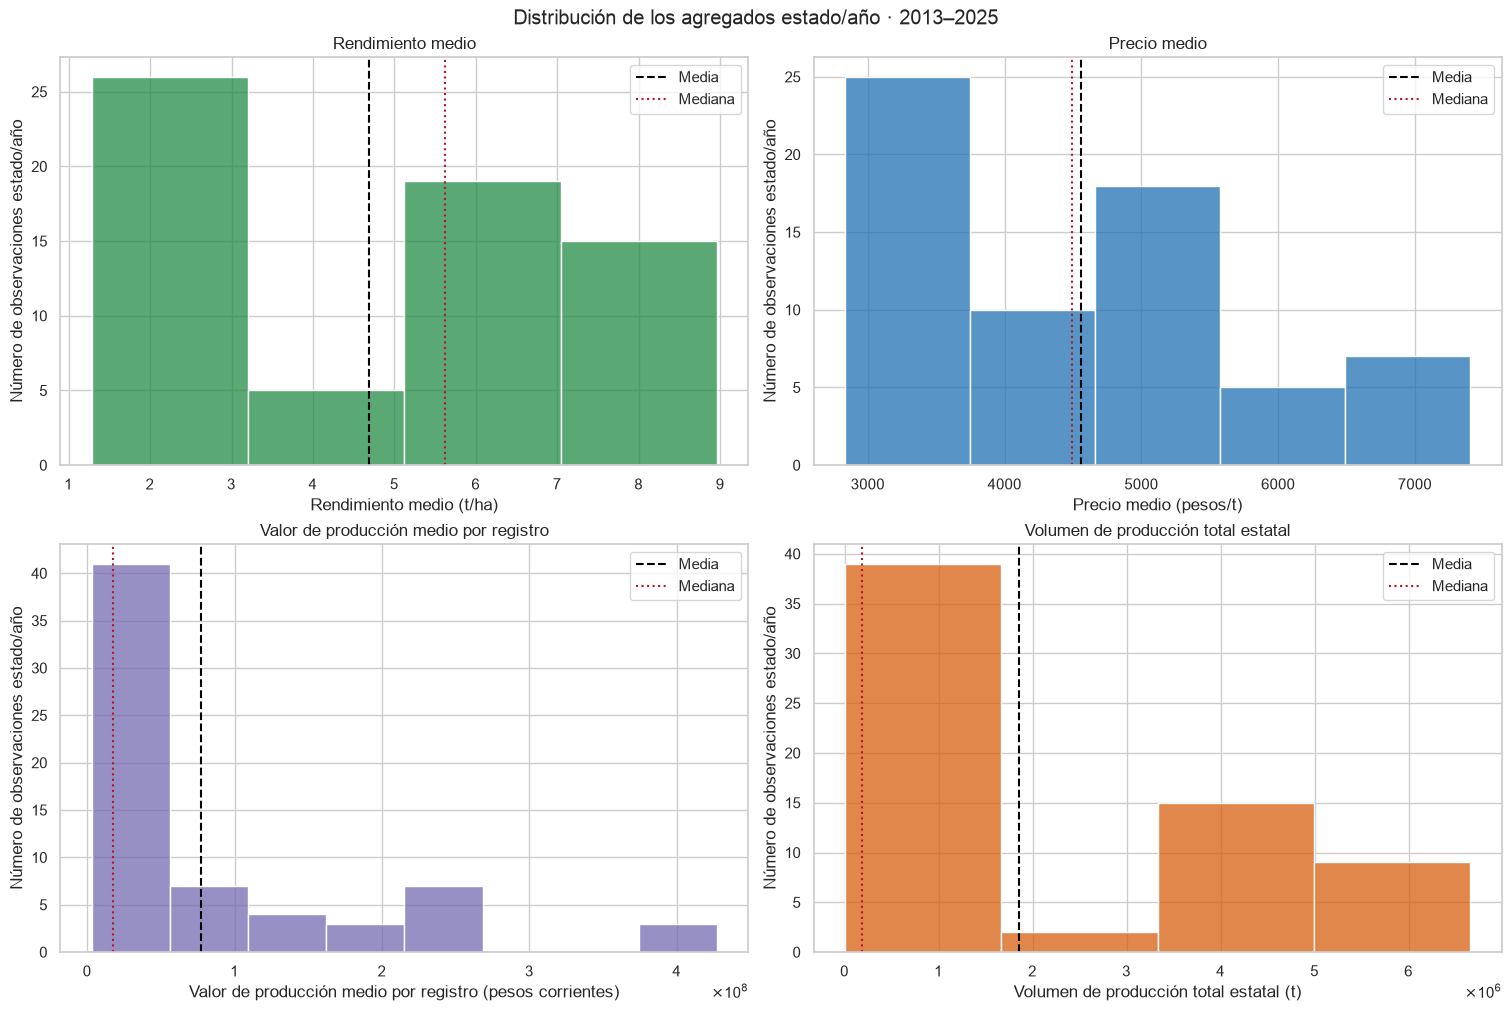

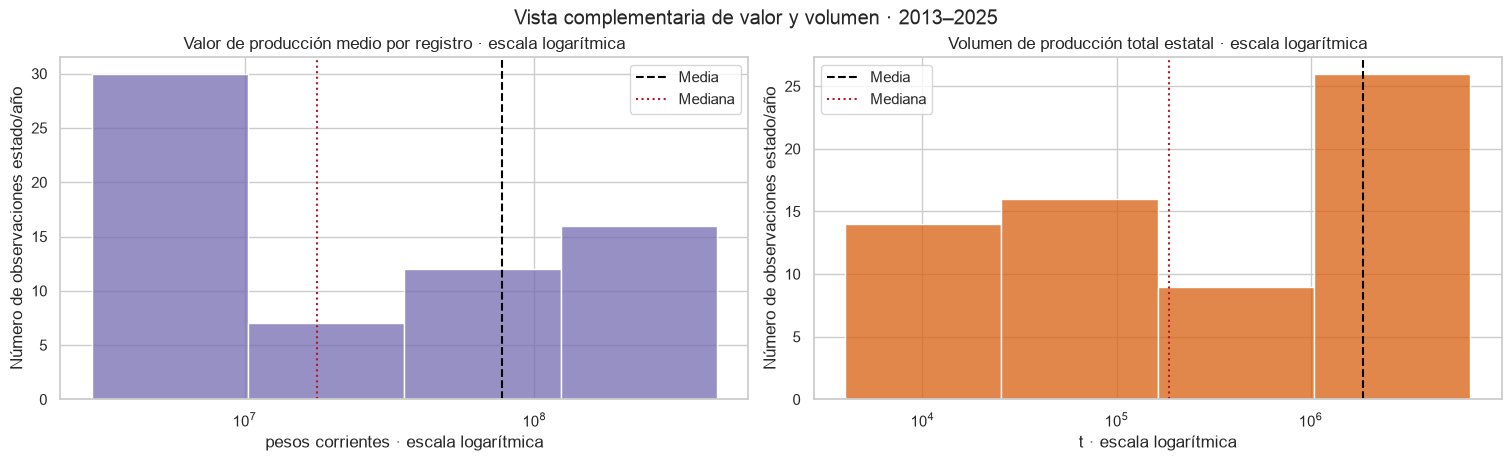

In [71]:
# Centralizamos nombres, unidades y colores para evitar etiquetas inconsistentes entre figuras.
especificaciones_univariables = {
    'Rendimiento': {'etiqueta': 'Rendimiento medio', 'unidad': 't/ha', 'color': '#238b45', 'paleta': 'Greens'},
    'Precio': {'etiqueta': 'Precio medio', 'unidad': 'pesos/t', 'color': '#2171b5', 'paleta': 'Blues'},
    'Valorproduccion': {'etiqueta': 'Valor de producción medio por registro', 'unidad': 'pesos corrientes', 'color': '#756bb1', 'paleta': 'Purples'},
    'Volumenproduccion': {'etiqueta': 'Volumen de producción total estatal', 'unidad': 't', 'color': '#d95f0e', 'paleta': 'Oranges'},
}
with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, ejes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
    for ax, (variable, tabla) in zip(ejes.flat, agregados_univariables.items()):
        especificacion = especificaciones_univariables[variable]
        sns.histplot(data=tabla, x=variable, bins='fd', color=especificacion['color'], ax=ax)
        ax.axvline(tabla[variable].mean(), color='black', linestyle='--', label='Media')
        ax.axvline(tabla[variable].median(), color='#b2182b', linestyle=':', label='Mediana')
        ax.set(title=especificacion['etiqueta'],
               xlabel=f"{especificacion['etiqueta']} ({especificacion['unidad']})",
               ylabel='Número de observaciones estado/año')
        ax.ticklabel_format(axis='x', style='sci', scilimits=(-3, 6), useMathText=True)
        ax.legend()
    fig.suptitle(f'Distribución de los agregados estado/año · {periodo_univariable}')
    plt.show()

    # La vista complementaria usa intervalos logarítmicos solo si no oculta ceros.
    fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
    for ax, variable in zip(ejes, ['Valorproduccion', 'Volumenproduccion']):
        tabla = agregados_univariables[variable]
        especificacion = especificaciones_univariables[variable]
        usar_log = bool(tabla[variable].gt(0).all())
        sns.histplot(data=tabla, x=variable, bins='fd', log_scale=usar_log,
                     color=especificacion['color'], ax=ax)
        ax.axvline(tabla[variable].mean(), color='black', linestyle='--', label='Media')
        ax.axvline(tabla[variable].median(), color='#b2182b', linestyle=':', label='Mediana')
        escala = 'logarítmica' if usar_log else 'lineal (incluye ceros)'
        ax.set(title=f"{especificacion['etiqueta']} · escala {escala}",
               xlabel=f"{especificacion['unidad']} · escala {escala}",
               ylabel='Número de observaciones estado/año')
        ax.legend()
    fig.suptitle(f'Vista complementaria de valor y volumen · {periodo_univariable}')
    plt.show()

#### 3.6 Boxplots: variación anual dentro de cada estado

Cada caja resume los **agregados anuales de un estado**: no representa la dispersión municipal. Ordenamos los estados por su mediana; dentro de cada figura, un tono más oscuro representa una mediana mayor. La intensidad no debe compararse entre variables con unidades diferentes.

La caja abarca Q1–Q3 y la línea interior indica la mediana. Los bigotes alcanzan los valores observados dentro de 1.5 RIC; los puntos exteriores se conservan y no se consideran automáticamente errores. Los cuartiles y bigotes se calculan en las unidades originales. En volumen y valor aplicamos después una escala logarítmica al eje para leer diferencias de magnitud; si hubiera ceros, se usaría una escala simétrica logarítmica con tramo lineal entre −1 y 1, conservándolos.

La variación entre años puede reflejar tendencias y cambios de composición, no solo variabilidad aleatoria.

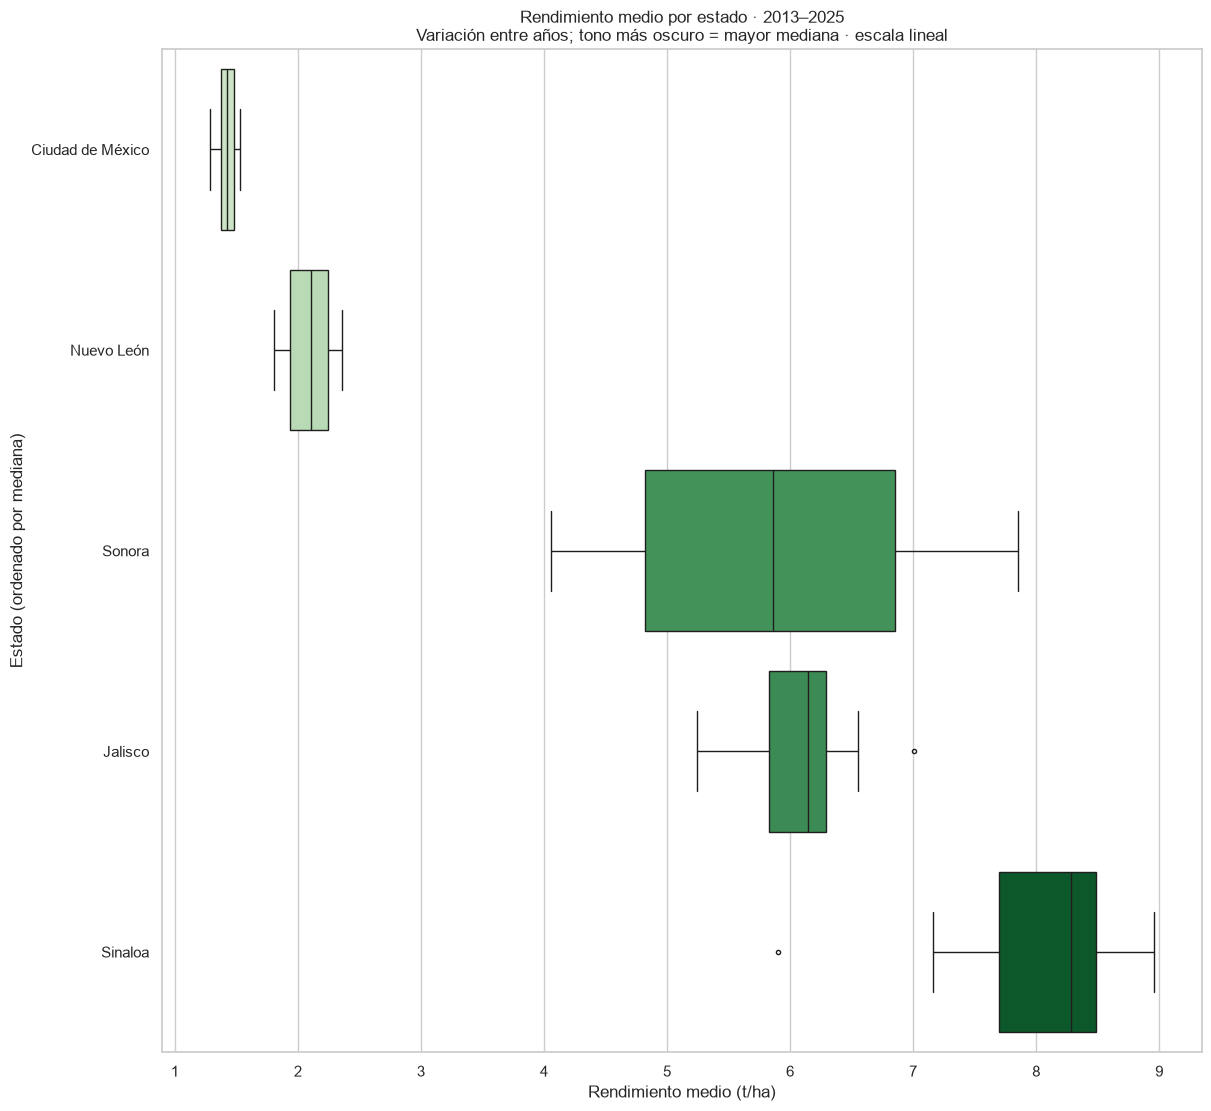

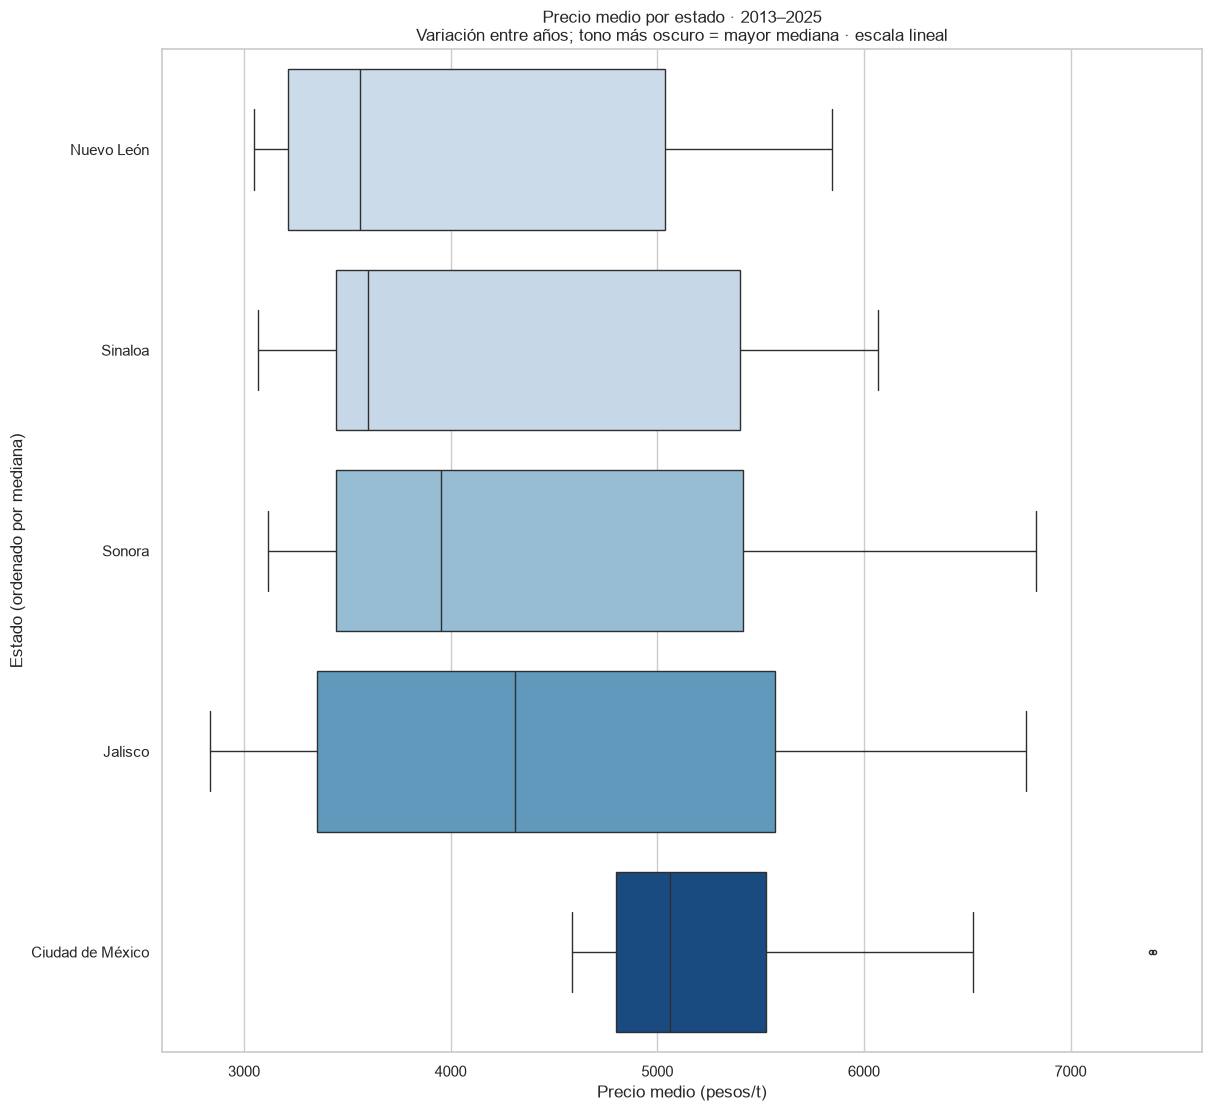

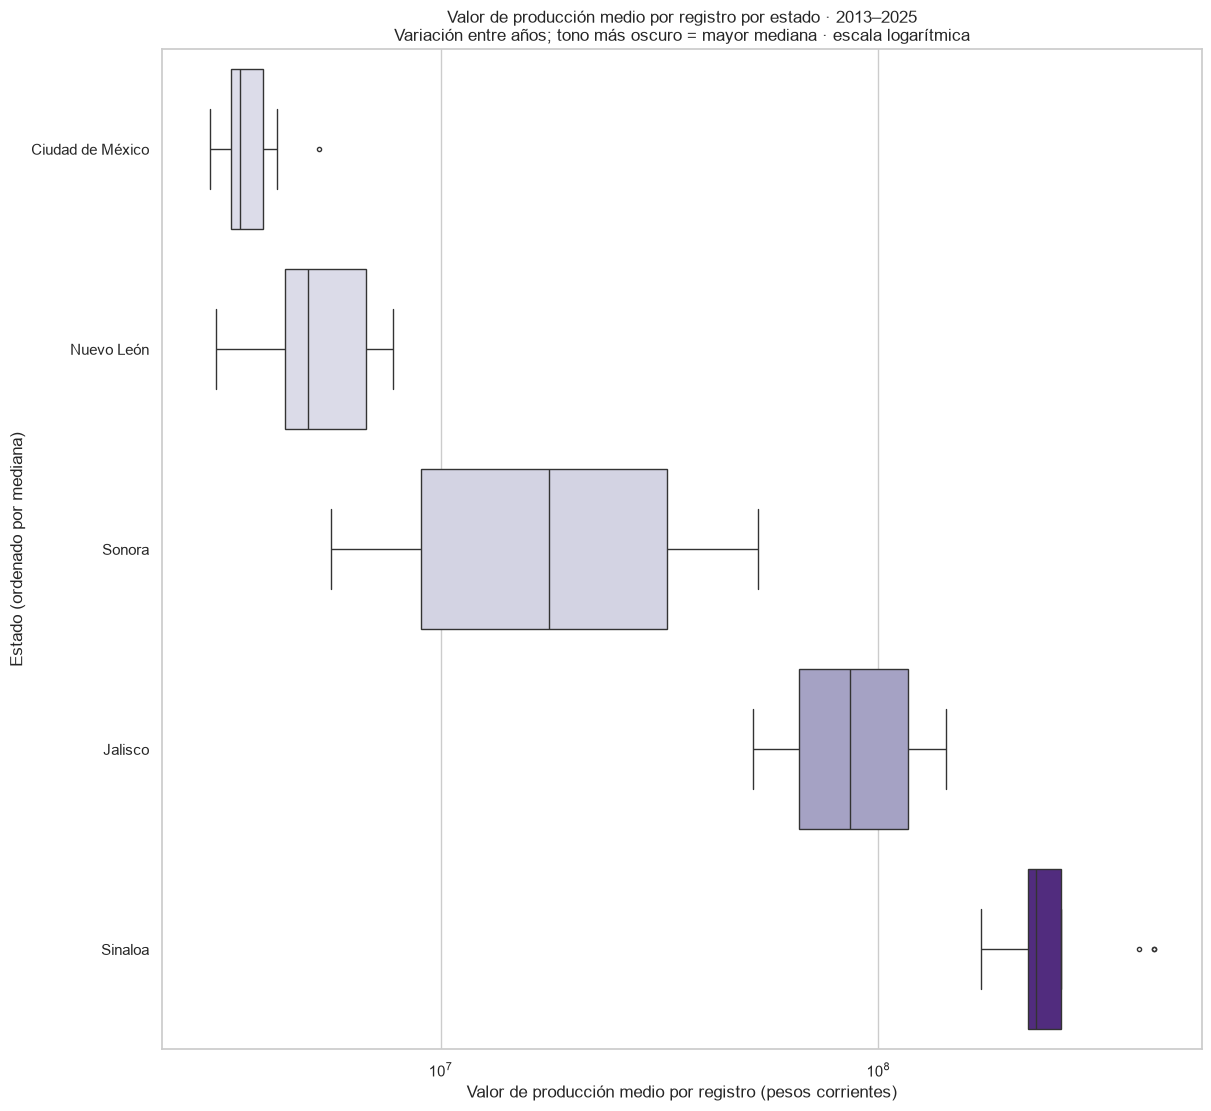

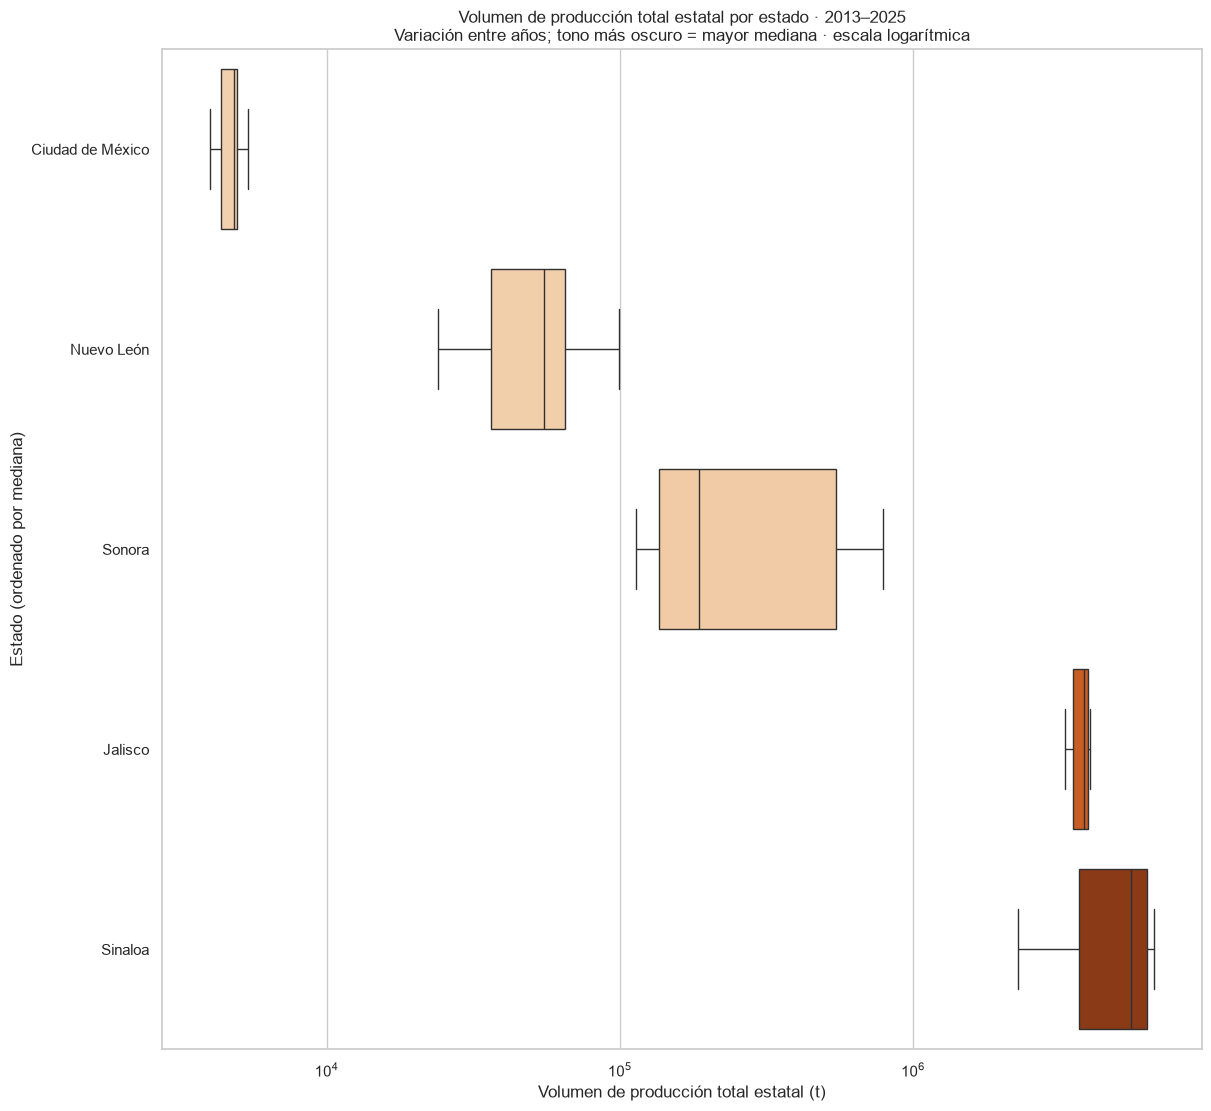

In [72]:
# Aplicamos la escala después del cálculo estadístico para conservar los cuartiles originales.
def escalar_magnitud_univariable(ax, valores, eje):
    escala = 'log' if valores.gt(0).all() else 'symlog'
    opciones = {} if escala == 'log' else {'linthresh': 1}
    if eje == 'x':
        ax.set_xscale(escala, **opciones)
    else:
        ax.set_yscale(escala, **opciones)
    return 'logarítmica' if escala == 'log' else 'simétrica logarítmica (tramo lineal ±1)'

with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    for variable, tabla in agregados_univariables.items():
        especificacion = especificaciones_univariables[variable]
        medianas = tabla.groupby('Nomestado')[variable].median().sort_values()
        normalizar_mediana = Normalize(vmin=medianas.min(), vmax=medianas.max())
        mapa_color = sns.color_palette(especificacion['paleta'], as_cmap=True)
        # Evitamos el extremo blanco de la paleta y asignamos intensidad según la mediana.
        colores_mediana = {
            estado: mapa_color(0.25 + 0.65 * float(normalizar_mediana(mediana)))
            for estado, mediana in medianas.items()
        }
        fig, ax = plt.subplots(figsize=(12, 11), constrained_layout=True)
        sns.boxplot(data=tabla, x=variable, y='Nomestado', order=medianas.index,
                    hue='Nomestado', hue_order=medianas.index, palette=colores_mediana,
                    dodge=False, legend=False, whis=1.5, showfliers=True, fliersize=3, ax=ax)
        escala = 'lineal'
        if variable in ['Valorproduccion', 'Volumenproduccion']:
            escala = escalar_magnitud_univariable(ax, tabla[variable], 'x')
        ax.set(title=f"{especificacion['etiqueta']} por estado · {periodo_univariable}\n"
                     f'Variación entre años; tono más oscuro = mayor mediana · escala {escala}',
               xlabel=f"{especificacion['etiqueta']} ({especificacion['unidad']})",
               ylabel='Estado (ordenado por mediana)')
        plt.show()

#### 3.7 Evolución temporal: un punto por estado y año

Las cuatro figuras utilizan directamente los dataframes creados en 3.2. Cada punto representa el agregado de un estado en un año. El eje horizontal conserva los años enteros y **cada estado mantiene el mismo color en todas las figuras**; aquí el color identifica una categoría y no una magnitud.

Mostramos todos los estados, con la leyenda fuera del área de datos. La superposición de puntos cercanos no implica falta de cobertura; la tabla de conteos permite verificarla. En volumen y valor se explicita la escala logarítmica (o simétrica logarítmica si hubiera ceros). Las diferencias verticales en escala logarítmica representan razones, no diferencias absolutas iguales.

Los precios y valores están expresados en **pesos corrientes**: sus variaciones no equivalen a cambios reales ajustados por inflación. Estos gráficos describen patrones, sin atribuir causalidad.

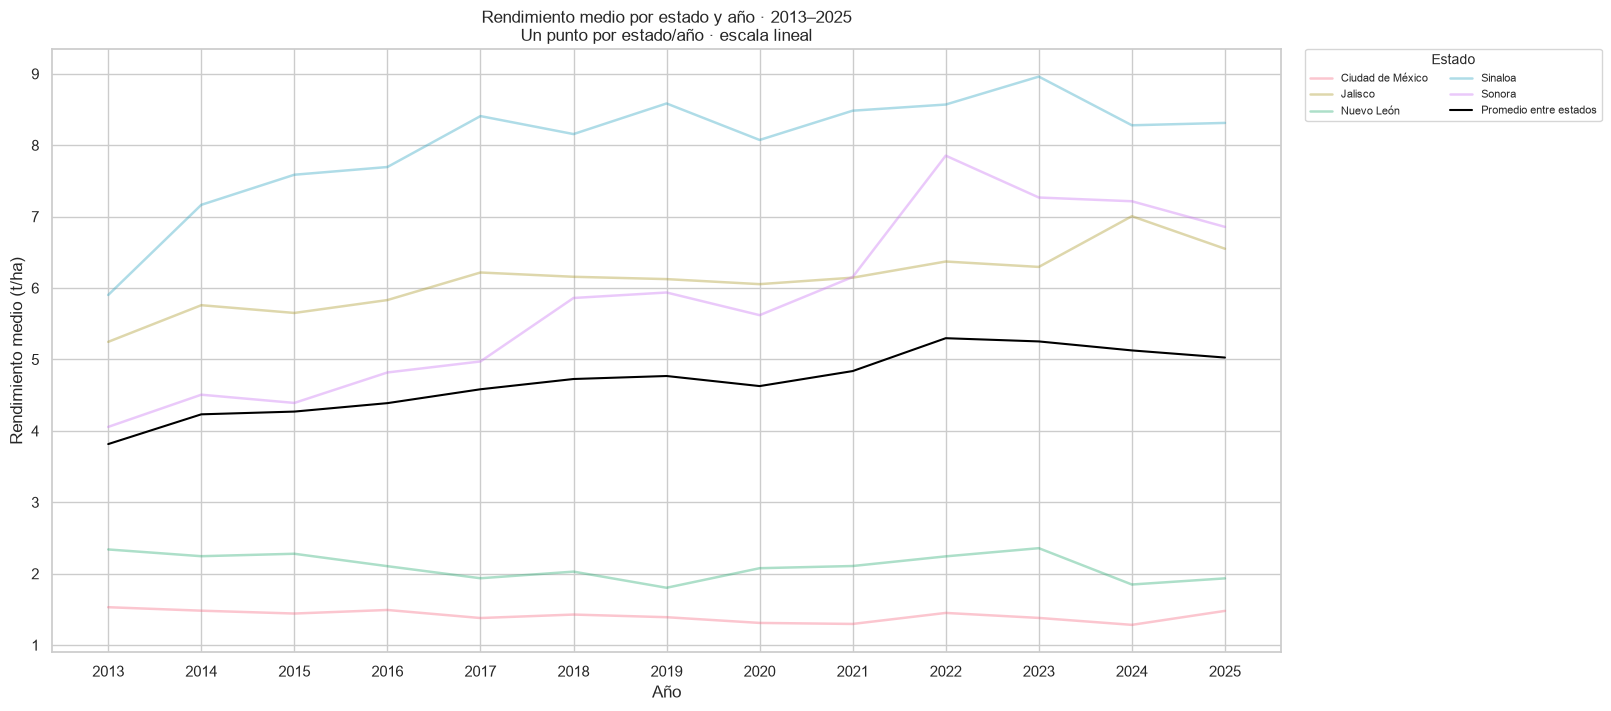

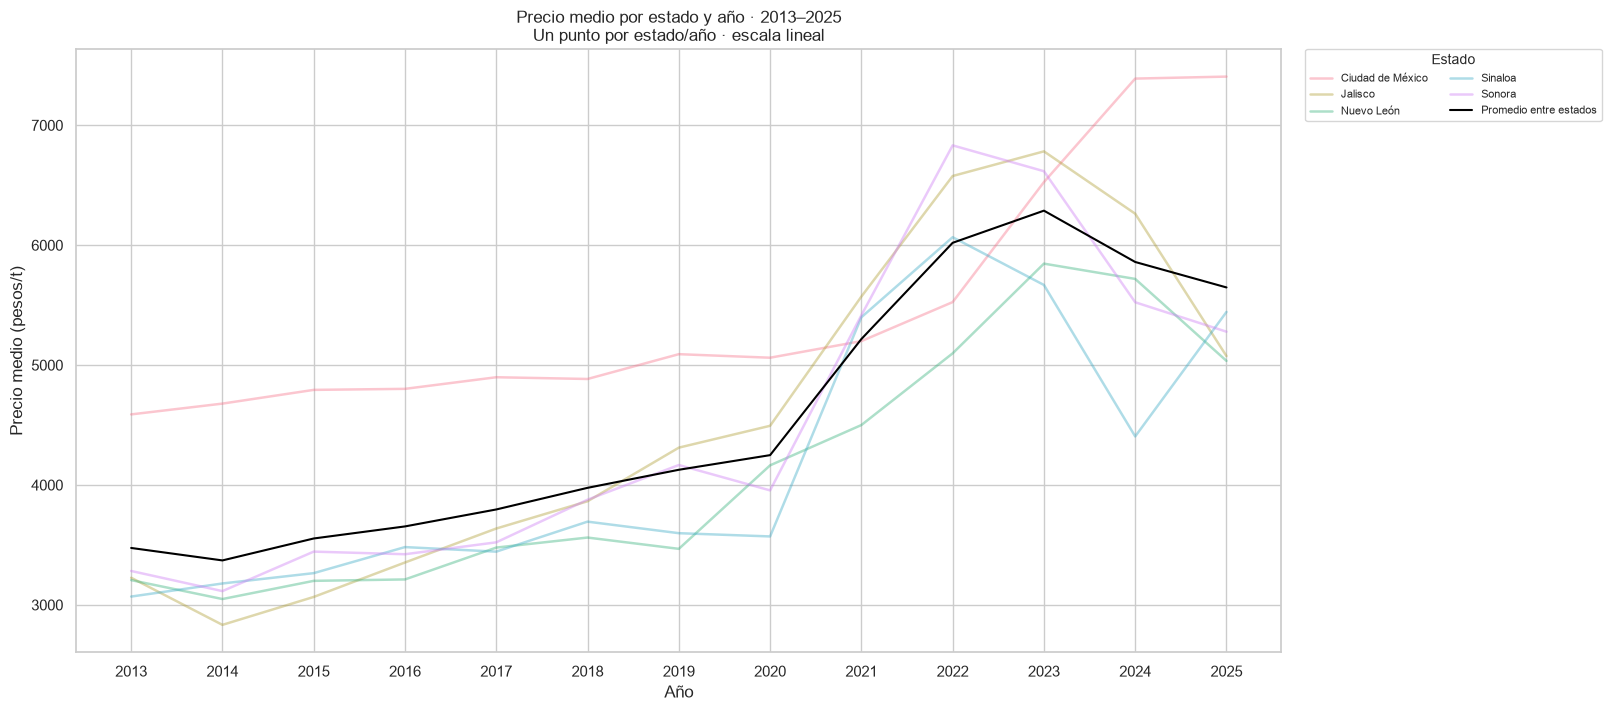

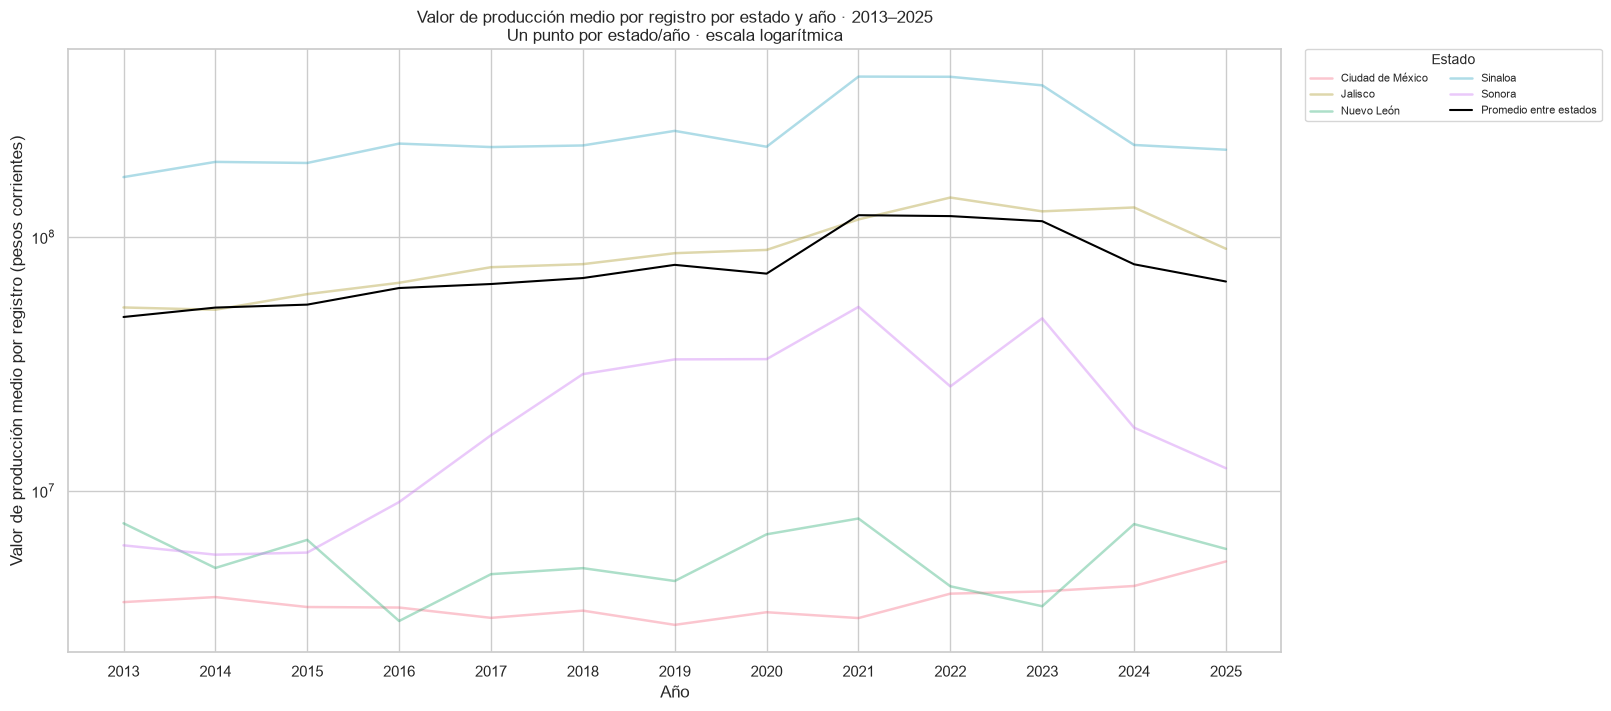

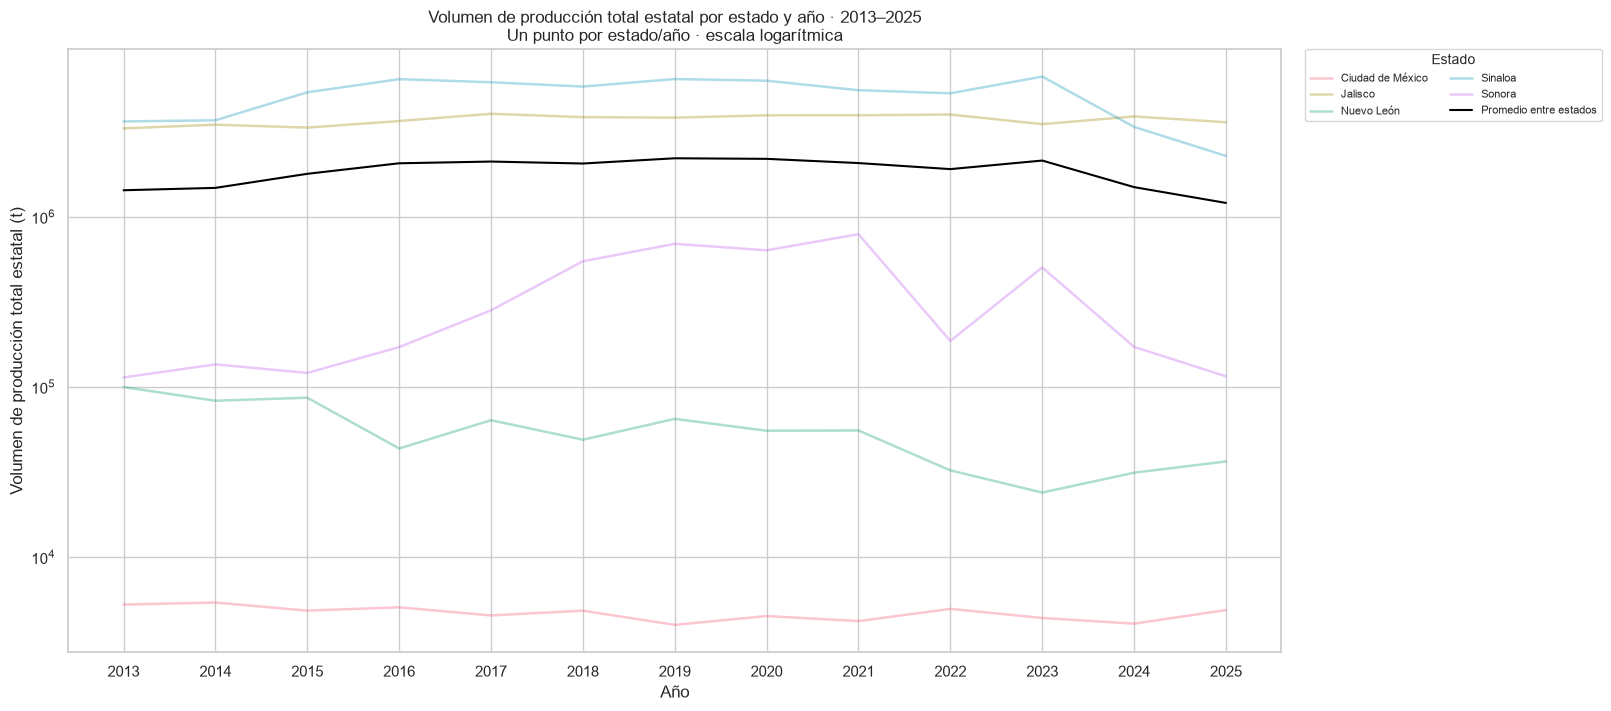

In [73]:
### MARKER 1.0 ###
# Fijamos una paleta categórica única para identificar los estados en las cuatro figuras.
estados_univariables = sorted(maiz_univariable.Nomestado.unique())
paleta_estados_univariable = dict(zip(
    estados_univariables, sns.color_palette('husl', n_colors=len(estados_univariables))
))
with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    for variable, tabla in agregados_univariables.items():
        especificacion = especificaciones_univariables[variable]
        fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
        sns.lineplot(data=tabla, x='Anio', y=variable, hue='Nomestado',
                        hue_order=estados_univariables, palette=paleta_estados_univariable,
                        estimator=None, errorbar=None, sort=True,
                        marker=None, alpha=0.4, linewidth=1.8,
                        legend='full', ax=ax)
        sns.lineplot(data=tabla, x='Anio', y=variable, estimator='mean', errorbar=None, sort=True, color='black', linewidth=1.5, label='Promedio entre estados', ax=ax)
        escala = 'lineal'
        if variable in ['Valorproduccion', 'Volumenproduccion']:
            escala = escalar_magnitud_univariable(ax, tabla[variable], 'y')
        ax.set_xticks(anios_univariables)
        ax.set(title=f"{especificacion['etiqueta']} por estado y año · {periodo_univariable}\n"
                     f'Un punto por estado/año · escala {escala}',
               xlabel='Año', ylabel=f"{especificacion['etiqueta']} ({especificacion['unidad']})")
        ax.legend(title='Estado', bbox_to_anchor=(1.02, 1), loc='upper left',
                  ncol=2, fontsize=8, title_fontsize=10, borderaxespad=0)
        plt.show()

#### 3.8 Lectura de los resultados y límites del análisis

El resumen siguiente se calcula a partir de las tablas, para que las conclusiones se actualicen al ejecutar el notebook. Describe la asimetría, el estado con mayor mediana anual en cada variable y la diferencia entre el primer y el último año usando **los mismos estados observados en ambos extremos**. Esta última comparación no resume todos los movimientos intermedios ni demuestra una tendencia monotónica. Para las tres variables promediadas, no equivale al crecimiento de un indicador nacional ponderado; para volumen, si se conservan los 32 estados, el cambio porcentual de su promedio coincide con el de la producción nacional total.

Las medias de rendimiento, precio y valor no son indicadores ponderados. El promedio entre estados da el mismo peso a cada estado, independientemente de su superficie, registros o producción. Incluso cuando dos distribuciones se superponen, pueden existir diferencias importantes entre municipios, ciclos y modalidades que esta agregación oculta. Las series anuales repetidas de un mismo estado tampoco deben tratarse como muestras independientes para inferencia estadística.

In [74]:
# Generamos una interpretación verificable sin fijar manualmente cifras o rankings.
conclusiones_univariables = []
for variable, tabla in agregados_univariables.items():
    especificacion = especificaciones_univariables[variable]
    serie = tabla[variable]
    medianas = tabla.groupby('Nomestado')[variable].median()
    estado_mayor_mediana = medianas.idxmax()
    extremos = tabla.pivot(index='Nomestado', columns='Anio', values=variable)
    extremos = extremos[[anios_univariables[0], anios_univariables[-1]]].dropna()
    media_inicial, media_final = extremos.mean().to_numpy()
    cambio = 100 * (media_final / media_inicial - 1) if media_inicial != 0 else np.nan
    direccion = 'positiva' if serie.skew() > 0 else 'negativa' if serie.skew() < 0 else 'nula'
    conclusiones_univariables.append(
        f"- **{especificacion['etiqueta']}:** media de los agregados = {serie.mean():,.2f}, "
        f"mediana = {serie.median():,.2f} {especificacion['unidad']}; "
        f'asimetría {direccion} ({serie.skew():.2f}). La mayor mediana anual corresponde a '
        f'**{estado_mayor_mediana}** ({medianas.max():,.2f}). '
        f'Entre {anios_univariables[0]} y {anios_univariables[-1]}, el promedio simple de '
        f'los agregados de los {len(extremos)} estados comunes cambia **{cambio:+.2f}%**.'
    )
porcentaje_ceros = 100 * sin_produccion.mean()
conclusiones_univariables.append(
    f'- **Ceros:** {sin_produccion.sum():,} registros ({porcentaje_ceros:.2f}%) no tienen '
    'producción. Permanecen en el análisis principal; la tabla de sensibilidad muestra '
    'cuánto cambian las medias de rendimiento y precio al condicionar a producción positiva.'
)
display(Markdown('\n\n'.join(conclusiones_univariables)))

- **Rendimiento medio:** media de los agregados = 4.69, mediana = 5.62 t/ha; asimetría negativa (-0.01). La mayor mediana anual corresponde a **Sinaloa** (8.28). Entre 2013 y 2025, el promedio simple de los agregados de los 5 estados comunes cambia **+31.76%**.

- **Precio medio:** media de los agregados = 4,556.48, mediana = 4,493.68 pesos/t; asimetría positiva (0.55). La mayor mediana anual corresponde a **Ciudad de México** (5,061.44). Entre 2013 y 2025, el promedio simple de los agregados de los 5 estados comunes cambia **+62.53%**.

- **Valor de producción medio por registro:** media de los agregados = 77,172,091.20, mediana = 17,731,342.25 pesos corrientes; asimetría positiva (1.76). La mayor mediana anual corresponde a **Sinaloa** (228,889,485.44). Entre 2013 y 2025, el promedio simple de los agregados de los 5 estados comunes cambia **+37.93%**.

- **Volumen de producción total estatal:** media de los agregados = 1,854,409.75, mediana = 185,958.83 t; asimetría positiva (0.78). La mayor mediana anual corresponde a **Sinaloa** (5,535,561.11). Entre 2013 y 2025, el promedio simple de los agregados de los 5 estados comunes cambia **-15.77%**.

- **Ceros:** 52 registros (1.02%) no tienen producción. Permanecen en el análisis principal; la tabla de sensibilidad muestra cuánto cambian las medias de rendimiento y precio al condicionar a producción positiva.

#### 3.9 Comprobaciones de consistencia

Verificamos que los años observados coincidan exactamente con el intervalo inclusivo configurado, tanto en `maiz` como en cada agregado, sin admitir años posteriores a `DGSIAP_END_YEAR`. Verificamos que los cuatro dataframes tengan claves únicas, índices simples y la misma cobertura; contrastamos sus resultados con agregaciones directas y comprobamos que la suma de los volúmenes estatales anuales conserve la producción original. También verificamos la continuidad de Ciudad de México y la comparación condicionada a producción positiva. Estas comprobaciones validan las transformaciones añadidas, no sustituyen la validación de calidad de la fuente.

In [75]:
# Contrastamos las tablas accesibles con cálculos independientes sobre los registros.
operaciones_univariables = {
    'Rendimiento': 'mean', 'Precio': 'mean', 'Valorproduccion': 'mean', 'Volumenproduccion': 'sum'
}
assert anios_univariables == anios_esperados_dgsiap
assert maiz['Anio'].nunique() == DGSIAP_END_YEAR - DGSIAP_START_YEAR + 1
claves_esperadas = cobertura_estado_anio[claves_univariables]
for variable, tabla in agregados_univariables.items():
    assert sorted(tabla['Anio'].unique().tolist()) == anios_esperados_dgsiap
    assert not tabla.duplicated(claves_univariables).any()
    assert tabla.index.equals(pd.RangeIndex(len(tabla)))
    pd.testing.assert_frame_equal(tabla[claves_univariables], claves_esperadas)
    agrupacion_directa = maiz_univariable.groupby(claves_univariables)[variable]
    esperado = (agrupacion_directa.sum(min_count=1) if operaciones_univariables[variable] == 'sum'
                else agrupacion_directa.mean())
    pd.testing.assert_series_equal(tabla.set_index(claves_univariables)[variable], esperado)
np.testing.assert_allclose(volumenproduccion_estado_anio.Volumenproduccion.sum(),
                           maiz.Volumenproduccion.sum())
assert int(cobertura_estado_anio.SinProduccion.sum()) == int(maiz.Volumenproduccion.eq(0).sum())
assert cobertura_estado_anio.Registros.sum() == len(maiz)
assert 'Ciudad de México / DF' not in maiz_univariable.Nomestado.unique()
assert set(maiz_univariable.loc[maiz_univariable.Nomestado.eq('Ciudad de México'), 'Anio']) == set(
    maiz.loc[maiz.Idestado.eq(9), 'Anio']
)

# La comparación conserva todos los grupos y deja NaN cuando no hay producción positiva.
esperado_positivo = (maiz_univariable.loc[maiz_univariable.Volumenproduccion.gt(0)]
                     .groupby(claves_univariables)[['Rendimiento', 'Precio']].mean())
observado_positivo = comparacion_ceros_estado_anio.set_index(claves_univariables)[
    ['Rendimiento_positivo', 'Precio_positivo']
].rename(columns={'Rendimiento_positivo': 'Rendimiento', 'Precio_positivo': 'Precio'})
pd.testing.assert_frame_equal(observado_positivo, esperado_positivo.reindex(observado_positivo.index))
assert len(comparacion_ceros_estado_anio) == len(cobertura_estado_anio)
print('Comprobaciones correctas: agregados, cobertura, ceros y comparación condicionada.')

Comprobaciones correctas: agregados, cobertura, ceros y comparación condicionada.


### 4.0 Correlación Entre Variables


Conjuntamos las variables en un solo dataframe.

In [76]:
agregados_multivariables = (
    pd.concat(
        [df.set_index(['Nomestado', 'Anio']) for df in agregados_univariables.values()],
        axis=1
    )
    # .reset_index()
)

display(agregados_multivariables.head(50))

Rendimiento       Precio  Valorproduccion  \
Nomestado        Anio                                              
Ciudad de México 2013     1.530000  4588.737143     3.646553e+06   
                 2014     1.481429  4678.715714     3.817010e+06   
                 2015     1.441429  4793.194286     3.487688e+06   
                 2016     1.491429  4801.738571     3.471498e+06   
                 2017     1.378571  4898.654286     3.161782e+06   
                 2018     1.427143  4884.058571     3.375449e+06   
                 2019     1.390000  5091.001429     2.967002e+06   
                 2020     1.310000  5061.438571     3.327249e+06   
                 2021     1.295714  5199.827143     3.155448e+06   
                 2022     1.450000  5525.242857     3.936766e+06   
                 2023     1.380000  6525.958571     4.016809e+06   
                 2024     1.282857  7389.294286     4.220721e+06   
                 2025     1.478571  7405.860000     5.272416e+06   
Jalisco          2013     5.246425  3226.389741     5.270416e+07   
                 2014     5.759415  2833.528617     5.163511e+07   
                 2015     5.650978  3066.364946     5.947664e+07   
                 2016     5.831579  3353.659316     6.591689e+07   
                 2017     6.217500  3636.889286     7.591910e+07   
                 2018     6.157513  3864.224145     7.805725e+07   
                 2019     6.124922  4311.435855     8.620360e+07   
                 2020     6.054410  4493.679641     8.880895e+07   
                 2021     6.145179  5571.507333     1.170730e+08   
                 2022     6.371231  6576.782359     1.427553e+08   
                 2023     6.295657  6782.381313     1.259597e+08   
                 2024     7.005795  6262.353026     1.304839e+08   
                 2025     6.550354  5075.271869     8.972324e+07   
Nuevo León       2013     2.338913  3206.687609     7.450550e+06   
                 2014     2.244310  3048.876379     4.969254e+06   
                 2015     2.278542  3200.495208     6.410669e+06   
                 2016     2.104600  3212.359000     3.072937e+06   
                 2017     1.935510  3477.980204     4.697398e+06   
                 2018     2.028462  3561.640513     4.961033e+06   
                 2019     1.802319  3467.421449     4.415663e+06   
                 2020     2.076316  4163.904211     6.741824e+06   
                 2021     2.107000  4499.881333     7.780198e+06   
                 2022     2.242051  5097.845641     4.208774e+06   
                 2023     2.356667  5846.035897     3.512610e+06   
                 2024     1.848000  5718.522000     7.396490e+06   
                 2025     1.933889  5034.973056     5.904831e+06   
Sinaloa          2013     5.902857  3069.469143     1.718095e+08   
                 2014     7.165000  3178.664355     1.972157e+08   
                 2015     7.586630  3264.848370     1.953066e+08   
                 2016     7.694688  3482.133333     2.328112e+08   
                 2017     8.407835  3444.034536     2.255998e+08   
                 2018     8.156020  3694.310714     2.288895e+08   
                 2019     8.584778  3598.066111     2.612624e+08   
                 2020     8.073592  3570.949806     2.262320e+08   
                 2021     8.483636  5398.917143     4.272799e+08   
                 2022     8.569762  6066.583571     4.265828e+08   
                 2023     8.960938  5668.089583     3.947457e+08   

                       Volumenproduccion  
Nomestado        Anio                     
Ciudad de México 2013            5250.60  
                 2014            5399.66  
                 2015            4836.99  
                 2016            5059.65  
                 2017            4533.44  
                 2018            4834.45  
                 2019            3990.42  
                 2020            4495.92  
                 2021            4200.13  
             

### 4.1 Cambios porcentuales
Calculamos los cambios porcentuales de cada variable sobre el tiempo.


In [77]:
# Cambio porcentual interanual por estado; reindexamos para que un año faltante no se salte.
indice_estado_anio = pd.MultiIndex.from_product(
    [agregados_multivariables.index.unique('Nomestado'), anios_univariables],
    names=claves_univariables,
)
cambio_porcentual_multivariables = (
    agregados_multivariables[variables_univariables]
    .reindex(indice_estado_anio)
    .groupby(level='Nomestado', sort=True)
    .pct_change()
    .mul(100)
    .replace([np.inf, -np.inf], np.nan)  # Un año base en cero no tiene cambio definido.
)
display(cambio_porcentual_multivariables.head(26).round(2))

Rendimiento  Precio  Valorproduccion  Volumenproduccion
Nomestado        Anio                                                         
Ciudad de México 2013          NaN     NaN              NaN                NaN
                 2014        -3.17    1.96             4.67               2.84
                 2015        -2.70    2.45            -8.63             -10.42
                 2016         3.47    0.18            -0.46               4.60
                 2017        -7.57    2.02            -8.92             -10.40
                 2018         3.52   -0.30             6.76               6.64
                 2019        -2.60    4.24           -12.10             -17.46
                 2020        -5.76   -0.58            12.14              12.67
                 2021        -1.09    2.73            -5.16              -6.58
                 2022        11.91    6.26            24.76              17.97
                 2023        -4.83   18.11             2.03             -11.60
                 2024        -7.04   13.23             5.08              -7.40
                 2025        15.26    0.22            24.92              20.18
Jalisco          2013          NaN     NaN              NaN                NaN
                 2014         9.78  -12.18            -2.03               5.11
                 2015        -1.88    8.22            15.19              -3.85
                 2016         3.20    9.37            10.83               9.26
                 2017         6.62    8.45            15.17              10.33
                 2018        -0.96    6.25             2.82              -4.41
                 2019        -0.53   11.57            10.44              -0.75
                 2020        -1.15    4.23             3.02               3.26
                 2021         1.50   23.99            31.83               0.06
                 2022         3.68   18.04            21.94               0.98
                 2023        -1.19    3.13           -11.77             -12.19
                 2024        11.28   -7.67             3.59              10.96
                 2025        -6.50  -18.96           -31.24              -7.50

Graficamos los cambios porcentuales.

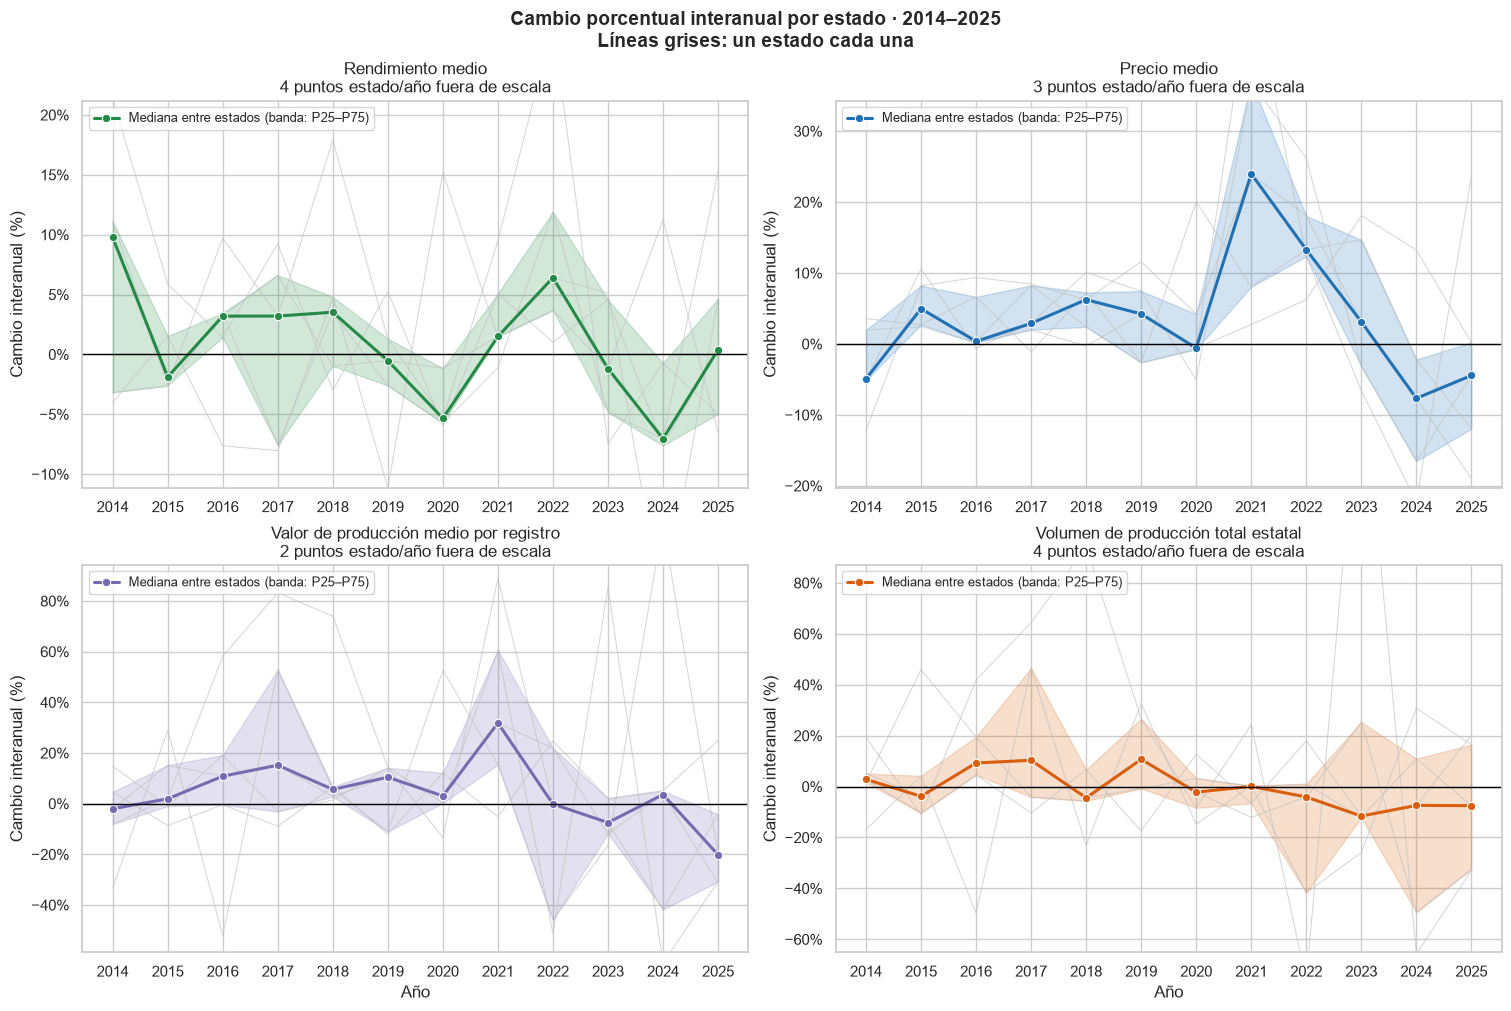

In [78]:
### M.2.1
# Línea de tiempo del cambio porcentual interanual: estados en gris, mediana y rango intercuartílico en color.
from matplotlib.ticker import PercentFormatter

cambio_porcentual_largo = (
    cambio_porcentual_multivariables
    .reset_index()
    .melt(id_vars=claves_univariables, var_name='Variable', value_name='Cambio')
    .dropna(subset=['Cambio'])
)
anios_cambio = anios_univariables[1:]  # El primer año no tiene año base.
with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, ejes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, constrained_layout=True)
    for ax, variable in zip(ejes.flat, variables_univariables):
        especificacion = especificaciones_univariables[variable]
        datos = cambio_porcentual_largo[cambio_porcentual_largo['Variable'].eq(variable)]
        sns.lineplot(data=datos, x='Anio', y='Cambio', units='Nomestado', estimator=None,
                     color='0.75', linewidth=0.8, alpha=0.6, ax=ax)
        sns.lineplot(data=datos, x='Anio', y='Cambio', estimator='median', errorbar=('pi', 50),
                     color=especificacion['color'], linewidth=2.2, marker='o', markersize=6,
                     label='Mediana entre estados (banda: P25–P75)', ax=ax)
        ax.axhline(0, color='black', linewidth=1)
        # Recortamos la escala a P2.5–P97.5 para que unos pocos saltos extremos no aplanen la serie.
        limite_inferior, limite_superior = datos['Cambio'].quantile([0.025, 0.975])
        margen = 0.05 * (limite_superior - limite_inferior)
        ax.set_ylim(limite_inferior - margen, limite_superior + margen)
        fuera_de_escala = (~datos['Cambio'].between(limite_inferior - margen, limite_superior + margen)).sum()
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        ax.set_xticks(anios_cambio)
        ax.tick_params(axis='x', labelbottom=True)
        ax.set(title=f"{especificacion['etiqueta']}\n{fuera_de_escala} puntos estado/año fuera de escala",
               xlabel='Año', ylabel='Cambio interanual (%)')
        ax.legend(loc='upper left', fontsize=9)
    fig.suptitle(f'Cambio porcentual interanual por estado · {anios_cambio[0]}–{anios_cambio[-1]}\n'
                 'Líneas grises: un estado cada una', fontsize=14, fontweight='bold')
    plt.show()


### 4.2 Correlación de Pearson
A partir de los cálculos pasados calculamos la matriz de correlación y graficamos un heatmap.

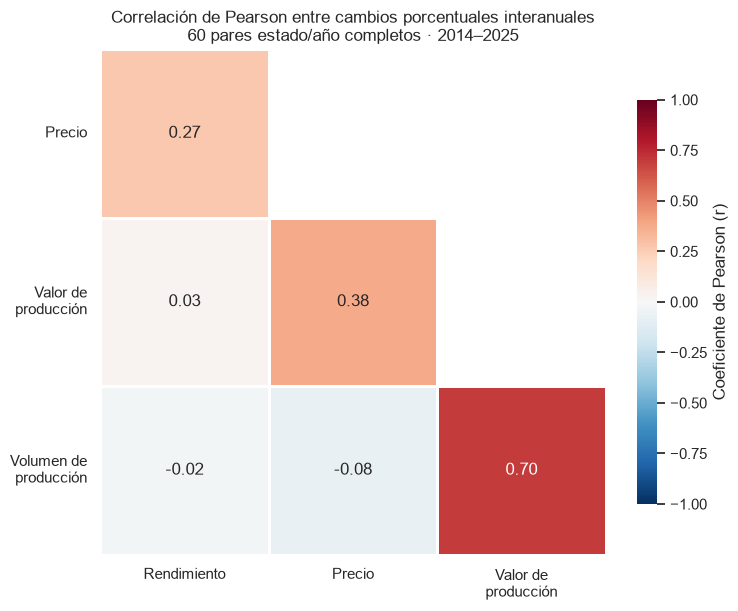

,Rendimiento,Precio,Valorproduccion,Volumenproduccion
Rendimiento,1.00,0.27,0.03,-0.02
Precio,0.27,1.00,0.38,-0.08
Valorproduccion,0.03,0.38,1.00,0.70
Volumenproduccion,-0.02,-0.08,0.70,1.00


In [79]:
### M.2.2
# Correlación de Pearson entre los cambios porcentuales interanuales, agrupando todos los pares estado/año.
etiquetas_cortas_multivariables = {
    'Rendimiento': 'Rendimiento', 'Precio': 'Precio',
    'Valorproduccion': 'Valor de\nproducción', 'Volumenproduccion': 'Volumen de\nproducción',
}
cambio_porcentual_completo = cambio_porcentual_multivariables[variables_univariables].dropna()
matriz_corr_cambio = (
    cambio_porcentual_completo
    .corr(method='pearson')
    .rename(index=etiquetas_cortas_multivariables, columns=etiquetas_cortas_multivariables)
)
# Conservamos solo el triángulo inferior sin la diagonal; la fila y columna vacías se recortan.
matriz_corr_inferior = matriz_corr_cambio.iloc[1:, :-1]
mascara_corr = np.triu(np.ones_like(matriz_corr_inferior, dtype=bool), k=1)
with sns.axes_style('white'), sns.plotting_context('notebook'):
    fig, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
    sns.heatmap(matriz_corr_inferior, mask=mascara_corr, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
                annot=True, fmt='.2f', annot_kws={'fontsize': 12}, square=True,
                linewidths=2, linecolor='white',
                cbar_kws={'label': 'Coeficiente de Pearson (r)', 'shrink': 0.8}, ax=ax)
    ax.tick_params(axis='x', rotation=0)
    ax.tick_params(axis='y', rotation=0)
    ax.set(title='Correlación de Pearson entre cambios porcentuales interanuales\n'
                 f'{len(cambio_porcentual_completo):,} pares estado/año completos · '
                 f'{anios_univariables[1]}–{anios_univariables[-1]}',
           xlabel='', ylabel='')
    plt.show()
display(cambio_porcentual_completo.corr(method='pearson').round(2))


### 4.3 Scatterplots

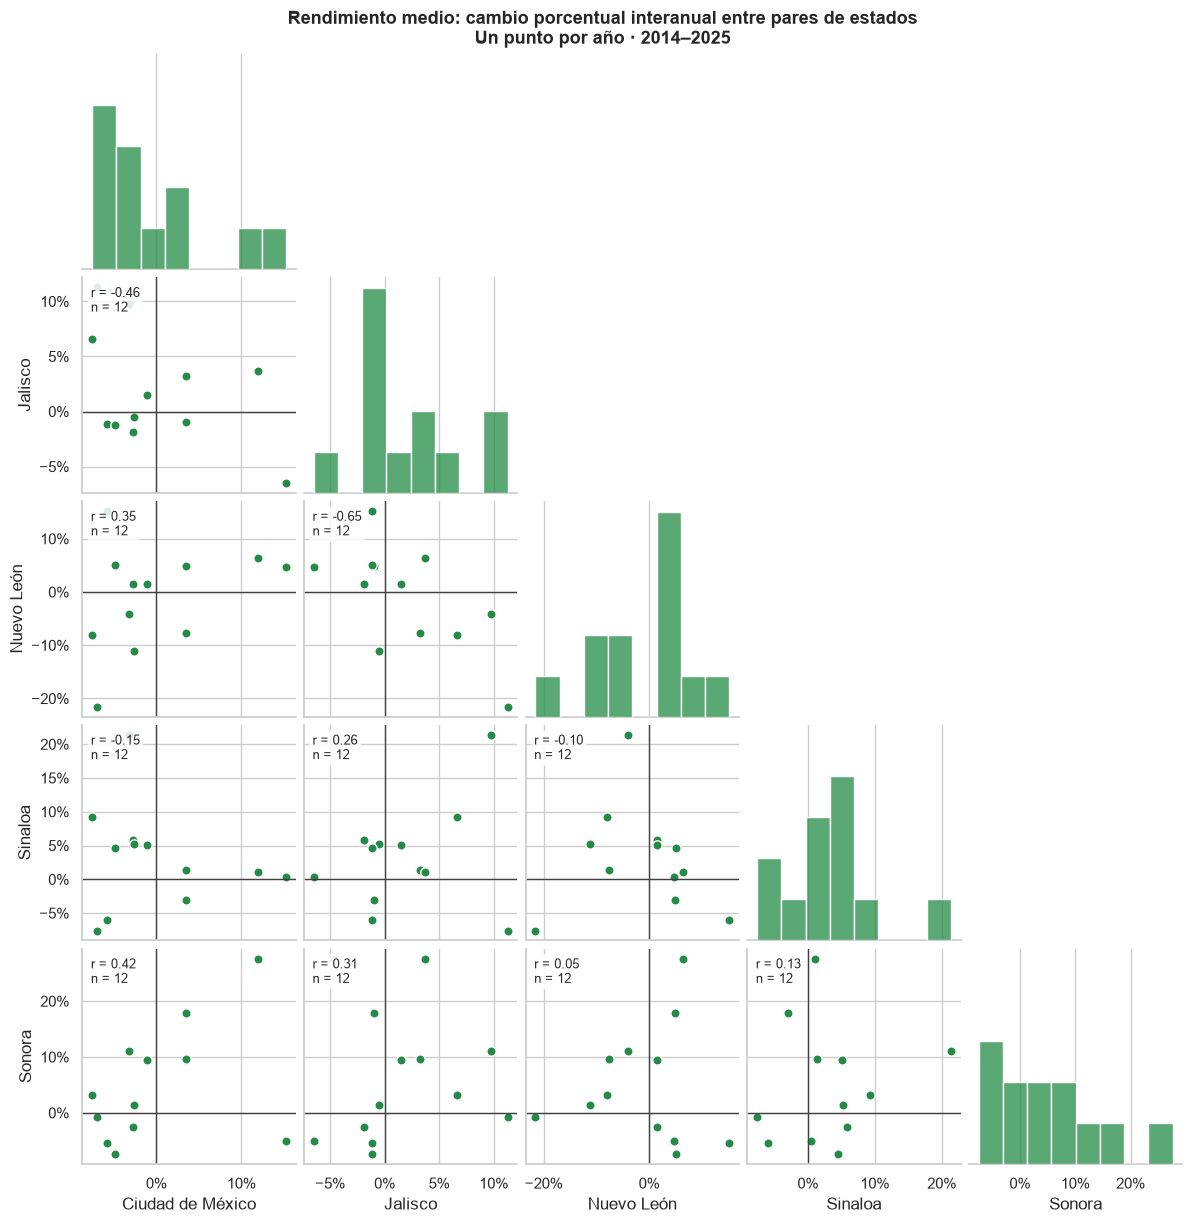

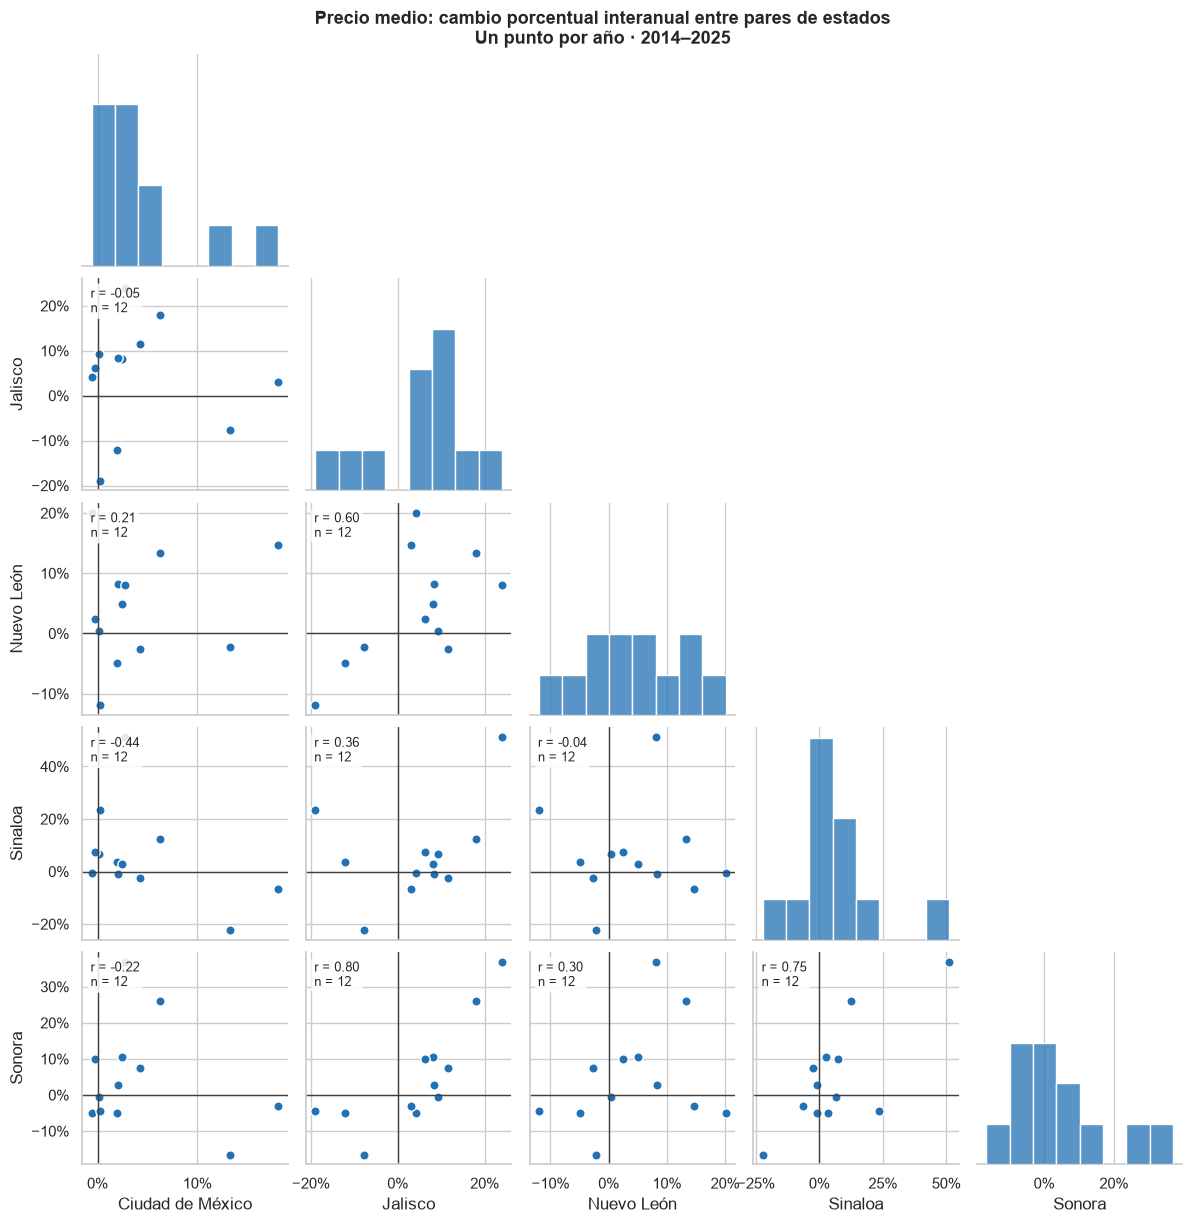

In [80]:
### M4.3
# Dispersión del cambio porcentual interanual entre cada par de estados: un punto por año.
def anotar_pearson_estados(x, y, **kwargs):
    ax = plt.gca()
    pares_completos = pd.concat([x, y], axis=1).dropna()
    r = pares_completos.iloc[:, 0].corr(pares_completos.iloc[:, 1])
    ax.axhline(0, color='0.25', linewidth=1, zorder=1)
    ax.axvline(0, color='0.25', linewidth=1, zorder=1)
    ax.annotate(f'r = {r:.2f}\nn = {len(pares_completos)}', xy=(0.04, 0.96), xycoords='axes fraction',
                ha='left', va='top', fontsize=9,
                bbox={'boxstyle': 'round,pad=0.25', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85})

for variable in variables_univariables[0:2]: # 'Precio', 'Volumenproduccion'
    especificacion = especificaciones_univariables[variable]
    # Pasamos a formato ancho: una fila por año y una columna por estado.
    cambio_por_estado = (
        cambio_porcentual_multivariables[variable]
        .unstack('Nomestado')
        .dropna(how='all')
        .rename_axis(columns=None)
    )
    with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
        rejilla = sns.pairplot(cambio_por_estado, corner=True, diag_kind='hist', height=2.4,
                               plot_kws={'color': especificacion['color'], 's': 45,
                                         'edgecolor': 'white', 'linewidth': 1},
                               diag_kws={'color': especificacion['color'], 'bins': 8})
        rejilla.map_lower(anotar_pearson_estados)
        for ax in rejilla.axes.flat:
            if ax is not None:
                ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
                ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        rejilla.figure.suptitle(
            f"{especificacion['etiqueta']}: cambio porcentual interanual entre pares de estados\n"
            f'Un punto por año · {cambio_por_estado.index.min()}–{cambio_por_estado.index.max()}',
            fontsize=13, fontweight='bold', y=1.02)
        plt.show()


### 5. Reducción de Características

In [81]:
### M5.1
# Construimos características no redundantes: Volumen y Valor se omiten porque derivan de ellas.
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

caracteristicas_pca = ['log_sembrada', 'tasa_siniestro', 'Rendimiento', 'log_precio']
etiquetas_pca = {
    'log_sembrada': 'log(1 + Sembrada)', 'tasa_siniestro': 'Tasa de siniestro',
    'Rendimiento': 'Rendimiento', 'log_precio': 'log(Precio)',
}
valido_pca = maiz['Sembrada'].gt(0) & maiz['Precio'].gt(0)
maiz_pca = (
    maiz.loc[valido_pca, ['Anio', 'Nomestado', 'Nomcicloproductivo', 'Nommodalidad',
                          'Sembrada', 'Siniestrada', 'Rendimiento', 'Precio']]
    .assign(
        Nomestado=lambda df: df['Nomestado'].replace({'Ciudad de México / DF': 'Ciudad de México'}),
        log_sembrada=lambda df: np.log1p(df['Sembrada']),
        tasa_siniestro=lambda df: (df['Siniestrada'] / df['Sembrada']).clip(upper=1),
        log_precio=lambda df: np.log(df['Precio']),
    )
    .dropna(subset=caracteristicas_pca)
    .reset_index(drop=True)
)
# Documentamos los registros excluidos en lugar de descartarlos en silencio.
display(pd.DataFrame({
    'Condición': ['Registros en maiz', 'Sin superficie sembrada', 'Precio cero',
                  'Precio cero y sin producción', 'Registros usados en el PCA'],
    'Registros': [len(maiz), maiz['Sembrada'].eq(0).sum(), maiz['Precio'].eq(0).sum(),
                  (maiz['Precio'].eq(0) & maiz['Volumenproduccion'].eq(0)).sum(), len(maiz_pca)],
}))
display(maiz_pca[caracteristicas_pca].describe().T.round(3))

,Condición,Registros
0,Registros en maiz,5094
1,Sin superficie sembrada,2
2,Precio cero,52
3,Precio cero y sin producción,52
4,Registros usados en el PCA,5042


,count,mean,std,min,25%,50%,75%,max
log_sembrada,5042.0,6.185,2.317,0.223,4.419,6.399,7.987,10.59
tasa_siniestro,5042.0,0.018,0.098,0.000,0.000,0.000,0.000,0.99
Rendimiento,5042.0,5.996,3.267,0.140,3.430,5.800,8.180,13.92
log_precio,5042.0,8.352,0.302,6.802,8.131,8.285,8.608,9.68


,Eigenvalor,Umbral paralelo (P95),Varianza explicada (%),Varianza acumulada (%)
PC1,1.447,1.051,36.160,36.160
PC2,1.011,1.021,25.272,61.431
PC3,0.967,1.000,24.176,85.608
PC4,0.576,0.982,14.392,100.000


**Componentes conservados (análisis paralelo):** 1 · 36.2% de la varianza.

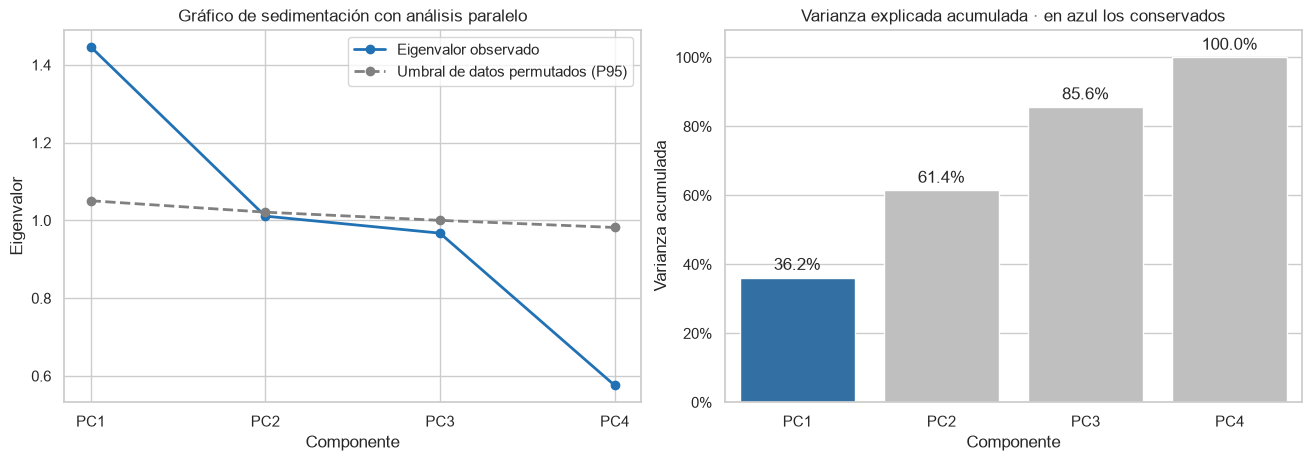

In [82]:
### M5.2
# Ajustamos estandarización + PCA y decidimos cuántos componentes conservar con análisis paralelo de Horn.
pipeline_pca = make_pipeline(StandardScaler(), PCA())
componentes_pca = pipeline_pca.fit_transform(maiz_pca[caracteristicas_pca])
pca = pipeline_pca.named_steps['pca']
nombres_componentes = [f'PC{i}' for i in range(1, len(caracteristicas_pca) + 1)]
maiz_pca[nombres_componentes] = componentes_pca

# Eigenvalores de datos con columnas permutadas: lo que se esperaría sin correlación entre variables.
generador_pca = np.random.default_rng(42)
matriz_estandar = pipeline_pca.named_steps['standardscaler'].transform(maiz_pca[caracteristicas_pca])
eigen_permutados = np.array([
    PCA().fit(np.column_stack([generador_pca.permutation(columna) for columna in matriz_estandar.T]))
    .explained_variance_
    for _ in range(200)
])
umbral_paralelo = np.percentile(eigen_permutados, 95, axis=0)
n_componentes_pca = int(np.cumprod(pca.explained_variance_ > umbral_paralelo).sum())

varianza_pca = pd.DataFrame({
    'Eigenvalor': pca.explained_variance_,
    'Umbral paralelo (P95)': umbral_paralelo,
    'Varianza explicada (%)': 100 * pca.explained_variance_ratio_,
    'Varianza acumulada (%)': 100 * pca.explained_variance_ratio_.cumsum(),
}, index=nombres_componentes)
np.testing.assert_allclose(pca.explained_variance_ratio_.sum(), 1)
np.testing.assert_allclose(matriz_estandar.mean(axis=0), 0, atol=1e-10)
display(varianza_pca.round(3))
display(Markdown(f'**Componentes conservados (análisis paralelo):** {n_componentes_pca} · '
                 f'{varianza_pca["Varianza acumulada (%)"].iloc[n_componentes_pca - 1]:.1f}% de la varianza.'))

with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, (ax_eigen, ax_acum) = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
    ax_eigen.plot(nombres_componentes, pca.explained_variance_, marker='o', linewidth=2,
                  color='#2171b5', label='Eigenvalor observado')
    ax_eigen.plot(nombres_componentes, umbral_paralelo, marker='o', linewidth=2, linestyle='--',
                  color='0.5', label='Umbral de datos permutados (P95)')
    ax_eigen.set(title='Gráfico de sedimentación con análisis paralelo', xlabel='Componente',
                 ylabel='Eigenvalor')
    ax_eigen.legend()
    colores_barras = ['#2171b5' if i < n_componentes_pca else '0.75' for i in range(len(nombres_componentes))]
    sns.barplot(x=nombres_componentes, y=varianza_pca['Varianza acumulada (%)'].to_numpy(),
                hue=nombres_componentes, palette=colores_barras, legend=False, ax=ax_acum)
    for contenedor in ax_acum.containers:
        ax_acum.bar_label(contenedor, fmt='%.1f%%', padding=3)
    ax_acum.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax_acum.set(title='Varianza explicada acumulada · en azul los conservados', xlabel='Componente',
                ylabel='Varianza acumulada', ylim=(0, 108))
    plt.show()


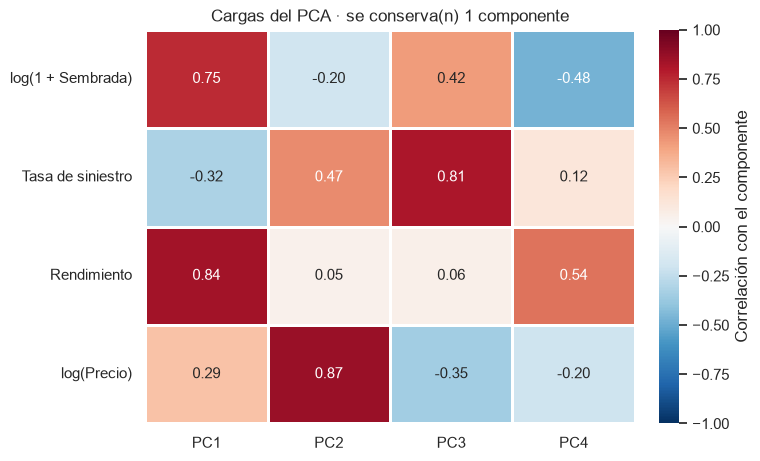

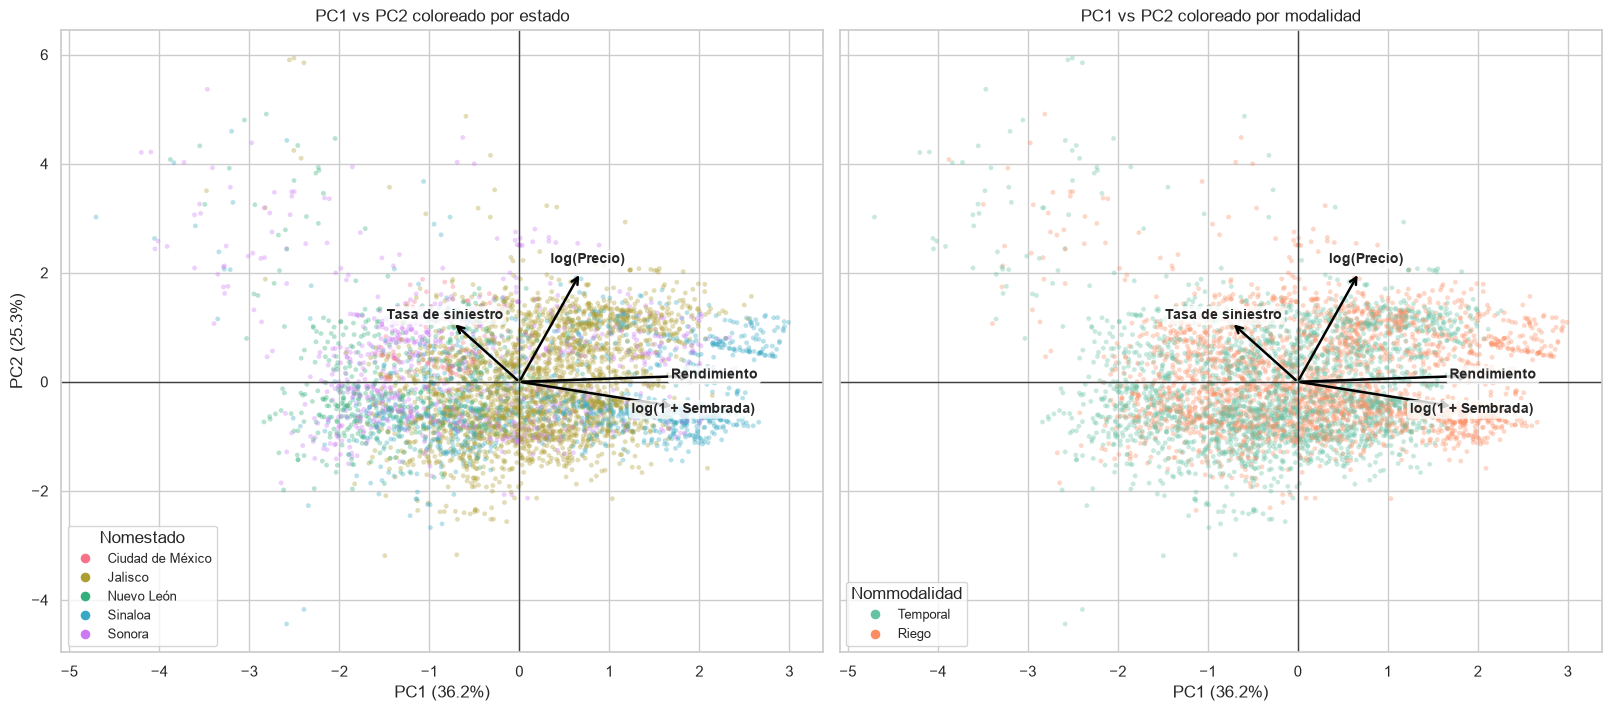

In [83]:
### M5.3
# Cargas como correlaciones variable–componente (válido porque las variables están estandarizadas).
cargas_pca = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=[etiquetas_pca[c] for c in caracteristicas_pca], columns=nombres_componentes,
)
with sns.axes_style('white'), sns.plotting_context('notebook'):
    fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
    sns.heatmap(cargas_pca, cmap='RdBu_r', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
                annot_kws={'fontsize': 11}, linewidths=2, linecolor='white',
                cbar_kws={'label': 'Correlación con el componente'}, ax=ax)
    ax.tick_params(axis='y', rotation=0)
    texto_conservados = 'componente' if n_componentes_pca == 1 else 'componentes'
    ax.set(title=f'Cargas del PCA · se conserva(n) {n_componentes_pca} {texto_conservados}', xlabel='', ylabel='')
    plt.show()

# Biplot: puntos por registro y flechas con las cargas, coloreado por estado y por modalidad.
escala_flechas = 0.8 * np.abs(maiz_pca[['PC1', 'PC2']]).quantile(0.99).min()
with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, ejes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True, constrained_layout=True)
    for ax, columna_color, titulo in zip(ejes, ['Nomestado', 'Nommodalidad'], ['estado', 'modalidad']):
        paleta = paleta_estados_univariable if columna_color == 'Nomestado' else 'Set2'
        sns.scatterplot(data=maiz_pca, x='PC1', y='PC2', hue=columna_color, palette=paleta,
                        s=12, alpha=0.35, linewidth=0, ax=ax)
        for variable, (carga_1, carga_2) in cargas_pca[['PC1', 'PC2']].iterrows():
            ax.annotate('', xy=(carga_1 * escala_flechas, carga_2 * escala_flechas), xytext=(0, 0),
                        arrowprops={'arrowstyle': '->', 'color': 'black', 'linewidth': 1.8})
            ax.text(carga_1 * escala_flechas * 1.12, carga_2 * escala_flechas * 1.12, variable,
                    ha='center', va='center', fontsize=10, fontweight='bold',
                    bbox={'boxstyle': 'round,pad=0.2', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.8})
        ax.axhline(0, color='0.25', linewidth=1)
        ax.axvline(0, color='0.25', linewidth=1)
        ax.set(title=f'PC1 vs PC2 coloreado por {titulo}',
               xlabel=f"PC1 ({varianza_pca.loc['PC1', 'Varianza explicada (%)']:.1f}%)",
               ylabel=f"PC2 ({varianza_pca.loc['PC2', 'Varianza explicada (%)']:.1f}%)")
        leyenda = ax.legend(title=columna_color, loc='lower left', fontsize=9, markerscale=2)
        for marca in leyenda.legend_handles:
            marca.set_alpha(1)
    plt.show()
